# MSI5001 – Airline Sentiment Clustering: 3 text representations × 3 clustering algorithms (v16)
**Goal:** group 14,639 airline tweets into **3 clusters** using only the tweet text, then check (afterwards) how well the clusters match `negative / neutral / positive`.

**Design**
- The former "extensions" are now part of the main workflow. Every step is done for **three representations** and **three algorithms**, giving a 3 × 3 grid of 9 clustering models:

| | K-Means | GMM | Ward agglomerative |
|---|---|---|---|
| **TF-IDF** (word counts) | ✓ | ✓ | ✓ |
| **Lexicon sentiment features** (VADER + question marks, 3, scaled) | ✓ | ✓ | ✓ |
| **MiniLM** sentence embeddings (`all-MiniLM-L6-v2`, 384-d) | ✓ | ✓ | ✓ |


- **Baseline:** TF-IDF + K-Means, the standard text-clustering pipeline (word counts clustered by K-Means). Every other model is judged by how much it improves on it.
- The notebook follows one logical path: **represent → measure distance → cluster (label-free choices) → evaluate → visualise → interpret → test the choices → uncertainty and robustness → takeaways.**

**Roadmap**
1. Setup and data
2. EDA on the text only
3. Text cleaning
4. Three representations: TF-IDF, lexicon sentiment features (VADER + question marks), MiniLM
5. Distance and scaling: how each representation "sees" three example tweets
6. Three clustering algorithms: K-Means (from scratch and scikit-learn), GMM, Ward; the input each one uses
7. Label-free model selection: k, GMM covariance (BIC), dendrograms
8. Fit the 9 models (TF-IDF + K-Means is the baseline)
9. Evaluation against the true labels (labels used **only** from here on)
10. Visualising clusters against the true sentiment
11. Interpreting the clusters
12. How the choices affect the results
13. Uncertainty and robustness
14. Save the models
15. Summary and key takeaways

> Rule from the README: `airline_sentiment` and `sentiment_confidence` are **never** used as model inputs or to make modelling choices. They appear for the first time in Section 9.

### Logic roadmap
```text
            Tweets.csv (14,639 tweets: text + sentiment label + confidence)
                                   |   labels set aside until Section 9
                                   v
 [2] EDA (text only) -> [3] cleaning: text_light (keeps !, ?, CAPS, emojis) / text_heavy (letters only)
                                   |
                                   v
 [4] REPRESENTATION: what does "similar" mean?
     TF-IDF (topic words) | Lexicon features (designed for sentiment) | MiniLM (general meaning)
                                   |
 [5] DISTANCE + SCALING: Euclidean on scaled features; cosine (= Euclidean on unit vectors) for text vectors
                                   |
 [6] ALGORITHM: K-Means (centroids) | GMM (soft, elliptical) | Ward (bottom-up merging)
 [7] label-free choices: k = 3, GMM covariance by BIC, dendrograms
                                   |
 [8] 9 models (baseline = TF-IDF + K-Means)
                                   |
 [9] EVALUATE (first use of labels): macro-F1 (primary), ARI, NMI, contingency tables
[10] VISUALISE: composition bars, heat-maps, t-SNE maps      [11] INTERPRET: centroids, words, example tweets
[12] CHOICES: representation, algorithm, scaling, GMM covariance & dimensions, linkage, features
[13] UNCERTAINTY & ROBUSTNESS: label confidence, GMM probabilities, seeds, subsamples, held-out tweets
                                   v
[15] TAKEAWAYS
```

### Definitions index
Technical terms are defined in **List of definitions_v16.csv**. Each section has a "Definitions used here" line giving the IDs.

- **A. Models:** A1 Baseline: TF-IDF + K-Means · A2 EM · A3 GMM · A4 K-Means · A5 K-Means from scratch · A6 k-means++ / n_init · A7 Agglomerative clustering
- **B. Representations and features:** B1 L2 normalisation · B2 N-grams · B3 PCA · B4 Sentence embedding · B5 Standardisation · B6 Question-mark count · B7 Text cleaning · B8 TF-IDF · B9 VADER scores · B10 Label-free feature screening · B11 Truncated SVD / LSA · B12 t-SNE
- **C. Evaluation metrics:** C1 ARI · C2 BIC · C3 Contingency table · C4 Hungarian matching · C5 Inertia / elbow · C6 Macro-F1 · C7 Matched accuracy · C8 NMI · C9 Purity · C10 Silhouette · C11 Spearman ρ · C12 Model-to-model agreement
- **D. Other terms:** D1 Confounder · D2 Cosine distance · D3 Euclidean distance · D4 Ablation study · D5 Label leakage · D6 Embedding cache · D7 Dequantisation (jitter) · D8 Curse of dimensionality

## 1. Setup and data

In [1]:
# In Colab, run this once:
# !pip install -q vaderSentiment sentence-transformers

import os, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             silhouette_score, f1_score, pairwise_distances)
from scipy.optimize import linear_sum_assignment
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage, dendrogram
from collections import Counter
warnings.filterwarnings('ignore')

SEED = 42                      # fixed seed so results are reproducible
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 160)

REPS  = ['TF-IDF', 'Lexicon features', 'MiniLM']                   # 3 representations
ALGOS = ['K-Means', 'GMM', 'Ward']                                   # 3 algorithms
SENT_COLORS = {'negative': '#c0504d', 'neutral': '#9e9e9e', 'positive': '#4f81bd'}
BASELINE = ('TF-IDF', 'K-Means')     # the baseline: standard text-clustering pipeline
def mname(rep, algo):
    return f'{rep} + {algo}' + (' (baseline)' if (rep, algo) == BASELINE else '')

In [2]:
# Files needed in the working folder (Colab: upload them, or mount Google Drive and cd into the project folder)
#   Tweets.csv                               – the dataset
#   tweet_embeddings_minilm.npy              – MiniLM cache   (optional: re-encoded if missing, ~1-3 min)
try:
    from google.colab import files
    if not os.path.exists('Tweets.csv'):
        files.upload()
except ImportError:
    pass                                       # running locally

df = pd.read_csv('Tweets.csv')
print(df.shape)
# Only the text is shown and used until Section 9; the label columns stay untouched until after clustering
df[['text']].head()

(14639, 3)


,text
0,@VirginAmerica What @dhepburn said.
1,@VirginAmerica plus you've added commercials to the experience... tacky.
2,@VirginAmerica I didn't today... Must mean I need to take another trip!
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have littl..."
4,@VirginAmerica and it's a really big bad thing about it


## 2. Explore the raw data (EDA), using the tweet text only
**Rule (README):** the sentiment label and the confidence score may only be used **after clustering**. Anything learned here can shape the representations, so this section looks at the `text` column **only**. The labels are described in Section 9.1.


> **Definitions used here** (see *List of definitions_v16.csv*): **D5** Label leakage · **B7** Text cleaning · **D1** Confounder · **B8** TF-IDF

In [3]:
text = df['text']                      # the ONLY column used in Sections 2-8
print('Tweets:', len(text), '| missing texts:', text.isna().sum())
print('Rows repeating an earlier text:', text.duplicated().sum(),
      '| distinct texts that appear more than once:', text[text.duplicated(keep=False)].nunique())
print('Retweets (start with "RT"):', text.str.startswith('RT').sum())

Tweets: 14639 | missing texts: 0
Rows repeating an earlier text: 213 | distinct texts that appear more than once: 187
Retweets (start with "RT"): 4


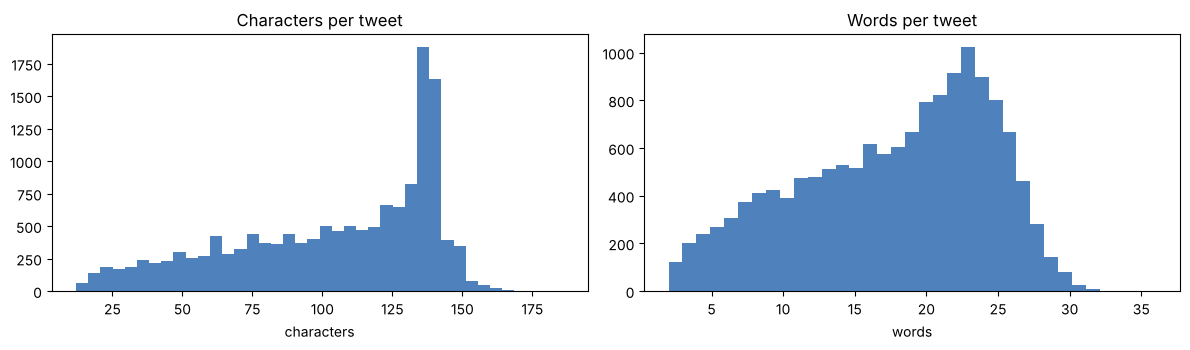

           count   mean   std   min   25%    50%    75%    max
n_chars  14639.0  103.8  36.3  12.0  77.0  114.0  136.0  186.0
n_words  14639.0   17.7   6.9   2.0  12.0   19.0   23.0   36.0
Share of tweets with 5 words or fewer: 0.057


In [4]:
df['n_chars'] = text.str.len()
df['n_words'] = text.str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(df['n_chars'], bins=40, color='#4f81bd'); ax[0].set_title('Characters per tweet'); ax[0].set_xlabel('characters')
ax[1].hist(df['n_words'], bins=35, color='#4f81bd'); ax[1].set_title('Words per tweet'); ax[1].set_xlabel('words')
plt.tight_layout(); plt.show()
print(df[['n_chars', 'n_words']].describe().round(1).T)
print('Share of tweets with 5 words or fewer:', round((df['n_words'] <= 5).mean(), 3))

In [5]:
# Read a random sample of tweets (text only)
for t in text.sample(8, random_state=1): print('-', t)

- @USAirways I been on hold with U for 40mins wasting my time and $ &amp; I don't appreciate it #WheresTheCustomerServiceAt http://t.co/phI2IfNjIT
- @AmericanAir it was 1265 coming and next catching 2396 home to DCA. Let's get another great leg too tonight!
- @SouthwestAir @Kaneshow @InternJohnRadio @mrerickv THIS IS EVERYTHING... now, return that jet so we can go to Miami!
- @AmericanAir I'm sure all these birds will be in warmer weather soon.
- @united we followed the baggage rules on your website and was still charges $150. But only going one way
- @JetBlue the best airline in the world
- @AmericanAir my flight is Cancelled Flightled and we can only call in but you aren't accepting calls? How do I reschedule my flight?
- @AmericanAir yes I do I am traveling to Marsh Harbor


### 2.1 Which airline is each tweet about?
Every tweet is addressed to an airline account. The airline is **who** the tweet is about, not **how** the writer feels, so @mentions are removed before building any representation (Section 3). Whether sentiment differs by airline is checked later, with the labels (Section 9.1).

In [6]:
AIRLINES = {'united': 'United', 'usairways': 'US Airways', 'americanair': 'American',
            'southwestair': 'Southwest', 'jetblue': 'JetBlue', 'virginamerica': 'Virgin America'}
def find_airline(t):
    for m in re.findall(r'@(\w+)', t.lower()):
        if m in AIRLINES: return AIRLINES[m]
    return 'Other / none'
df['airline'] = text.apply(find_airline)
print(df['airline'].value_counts())

airline
United            3821
US Airways        2913
American          2759
Southwest         2421
JetBlue           2218
Virgin America     503
Other / none         4
Name: count, dtype: int64


### 2.2 Punctuation, emphasis and Twitter elements
How common is each cue of tone? Only frequent cues are worth a separate feature.

In [7]:
EMOJI = r'[\U0001F300-\U0001FAFF☀-➿]'
NEG_RE = r"\b(?:not|no|never|nothing|nobody|none|cannot|\w+n't)\b"
elements = pd.DataFrame({
    'has "!"':          text.str.contains('!'),
    'has "?"':          text.str.contains(r'\?'),
    'has ALL-CAPS word':text.str.contains(r'\b[A-Z]{2,}\b'),
    'has negation':     text.str.lower().str.contains(NEG_RE),
    'has hashtag':      text.str.contains(r'#\w+'),
    'has URL':          text.str.contains('http'),
    'has emoji':        text.str.contains(EMOJI),
    'has emoticon':     text.str.contains(r'(?::|;|=)-?[)(DPp]'),
    'repeated letters': text.str.contains(r'([a-zA-Z])\1{2,}'),
})
elements.mean().sort_values(ascending=False).round(3).to_frame('share of tweets')

,share of tweets
has negation,0.325
has ALL-CAPS word,0.268
"has ""?""",0.251
"has ""!""",0.220
has hashtag,0.162
has URL,0.080
has emoji,0.033
has emoticon,0.024
repeated letters,0.007


### 2.3 What are the ALL-CAPS words?

In [8]:
no_handles = text.str.replace(r'http\S+|@\w+|#\w+', ' ', regex=True)
caps = Counter(w for t in no_handles for w in re.findall(r'\b[A-Z]{2,}\b', t))
print(f'{sum(caps.values()):,} ALL-CAPS tokens; most common 30:')
print(caps.most_common(30))

6,199 ALL-CAPS tokens; most common 30:
[('DM', 248), ('AA', 197), ('JFK', 166), ('US', 146), ('DFW', 133), ('LAX', 125), ('SFO', 108), ('ORD', 106), ('PHL', 100), ('DCA', 94), ('RT', 93), ('BOS', 80), ('EWR', 80), ('CLT', 79), ('NYC', 67), ('IAD', 59), ('UA', 57), ('FLL', 54), ('LGA', 53), ('NOT', 51), ('YOU', 50), ('PHX', 50), ('CEO', 48), ('IAH', 47), ('DC', 45), ('THE', 45), ('NO', 44), ('SW', 44), ('BWI', 43), ('DEN', 43)]


### 2.4 Vocabulary: what do people write about?

Vocabulary size: 10,887 words | used in only one tweet: 50%
Average distinct words per tweet: 7.9


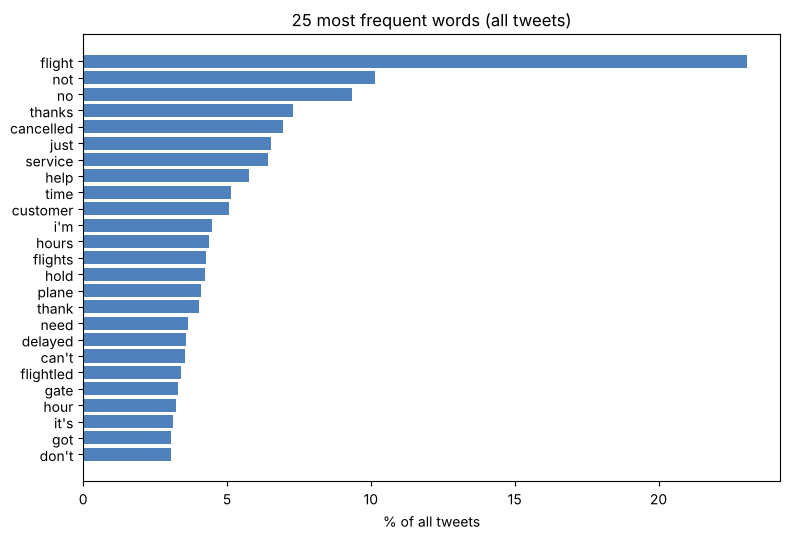

In [9]:
raw = text.str.replace(r'http\S+|@\w+|&\w+;', ' ', regex=True).str.lower()
stop = list(ENGLISH_STOP_WORDS - {'not', 'no', 'never', 'nothing', 'cannot'})
cv = CountVectorizer(stop_words=stop, token_pattern=r"(?u)\b[a-z][a-z']+\b")
counts = cv.fit_transform(raw)
vocab_cv = np.array(cv.get_feature_names_out())
df_freq = np.asarray((counts > 0).sum(axis=0)).ravel()
print(f'Vocabulary size: {len(vocab_cv):,} words | used in only one tweet: {(df_freq == 1).mean():.0%}')
print(f'Average distinct words per tweet: {(counts > 0).sum(axis=1).mean():.1f}')
top = np.argsort(df_freq)[::-1][:25]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(vocab_cv[top][::-1], df_freq[top][::-1] / len(text) * 100, color='#4f81bd')
ax.set_xlabel('% of all tweets'); ax.set_title('25 most frequent words (all tweets)')
plt.tight_layout(); plt.show()

**EDA observations (text only):**
- **Data quality:** no missing texts; 213 rows repeat an earlier text (kept, removing them barely changes results). Tweets average 17.7 words; about 6% have 5 words or fewer.
- **Airlines:** every tweet @mentions an airline (United 3,821 … Virgin America 503). @mentions are removed so no representation can group tweets by airline.
- **Cues of tone:** negations (32%), "?" (25%) and "!" (22%) are common; emojis (3%), emoticons (2%) and stretched words (<1%) are rare and are scored by VADER and read by the transformers anyway.
- **ALL-CAPS words are mostly not shouting** but airport/airline codes (JFK, DFW, AA) and "DM".
- **Vocabulary:** about 10,900 words, half used only once, about 8 per tweet: word-count vectors are extremely sparse, and the most frequent words are travel **topics** (flight, cancelled, service, hours, hold, gate). A word-count representation is therefore likely to group by topic, which motivates sentiment-oriented representations.

## 3. Clean the text

> **Definitions used here** (see *List of definitions_v16.csv*): **B7** Text cleaning

In [10]:
def clean(t):
    t = re.sub(r'http\S+', ' ', t)           # remove URLs
    t = re.sub(r'@\w+', ' ', t)              # remove @airline / @user mentions (airline is a confounder)
    t = t.replace('&amp;', '&').replace('&lt;', '<').replace('&gt;', '>')
    t = re.sub(r'#(\w+)', r'\1', t)          # '#fail' -> 'fail'
    t = re.sub(r'(.)\1{2,}', r'\1\1', t)      # 'soooo' -> 'soo'
    return re.sub(r'\s+', ' ', t).strip()

# Light cleaning: keeps case, '!', '?', emojis and negations -> VADER, the question-mark count and MiniLM
df['text_light'] = df['text'].apply(clean)
# Heavy cleaning: lower-case and letters only -> TF-IDF, which counts exact word forms
df['text_heavy'] = df['text_light'].str.lower().str.replace(r"[^a-z' ]", ' ', regex=True)
df[['text', 'text_light', 'text_heavy']].head()

,text,text_light,text_heavy
0,@VirginAmerica What @dhepburn said.,What said.,what said
1,@VirginAmerica plus you've added commercials to the experience... tacky.,plus you've added commercials to the experience.. tacky.,plus you've added commercials to the experience tacky
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,I didn't today.. Must mean I need to take another trip!,i didn't today must mean i need to take another trip
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have littl...","it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces & they have little recourse",it's really aggressive to blast obnoxious entertainment in your guests' faces they have little recourse
4,@VirginAmerica and it's a really big bad thing about it,and it's a really big bad thing about it,and it's a really big bad thing about it


## 4. Three ways to turn a tweet into numbers
Clustering algorithms only see vectors, so the representation **defines what "similar" means**. We compare three representations that differ in *who decides* what matters:

| # | Representation | Who decides what matters? | Size | Expected to group by |
|---|---|---|---|---|
| 4.1 | **TF-IDF** (unigrams + bigrams) | Word frequencies in this dataset | 16,511 sparse columns | Topic words |
| 4.2 | **Lexicon sentiment features** | A published sentiment lexicon (VADER) + one structure cue | 3 readable columns | The three tweet types in the README |
| 4.3 | **MiniLM** (`all-MiniLM-L6-v2`) | A transformer pre-trained for general sentence similarity | 384 dense dims | Overall meaning (topic + tone) |

None of them uses this dataset's labels: TF-IDF and the lexicon features are computed from the text, and MiniLM was pre-trained elsewhere and is used as a fixed text-to-numbers converter.

### 4.1 TF-IDF (word counts)
Each tweet becomes one column per word or two-word phrase; bigrams keep short word order ("not good"). Rows are L2-normalised, so Euclidean distance behaves like cosine distance.


> **Definitions used here** (see *List of definitions_v16.csv*): **B8** TF-IDF · **B2** N-grams · **B1** L2 normalisation

In [11]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True)
X_tfidf = tfidf.fit_transform(df['text_heavy'])
vocab = np.array(tfidf.get_feature_names_out())
print('TF-IDF matrix:', X_tfidf.shape, f'| non-zero entries: {X_tfidf.nnz / np.prod(X_tfidf.shape):.3%}')

TF-IDF matrix: (14639, 16511) | non-zero entries: 0.133%


### 4.2 Lexicon sentiment features: VADER + question marks
**Where the design comes from.** The README describes the tweets as *"praise, complaints, and neutral requests for information"*. We build one readable feature for each of these three tweet types:

| Tweet type (README) | Feature | Source | What it measures |
|---|---|---|---|
| Praise | `vader_pos` | **VADER** (Hutto & Gilbert, 2014), a published rule-based sentiment lexicon for social media | Share of the tweet's wording that is positive (0–1) |
| Complaints | `vader_neg` | VADER | Share of the tweet's wording that is negative (0–1) |
| Requests for information | `question_marks` | Punctuation | Number of "?" in the tweet |

**Design rules (no labels involved):**
1. **Only a published, general-purpose resource and a simple text cue** – no word lists written by us, nothing learned from this dataset.
2. **One feature per tweet type in the README**, so every cluster centre can be read directly ("how positive / how negative / how questioning").
3. **No duplicated cues.** VADER's scoring rules already use negation ("not good"), intensifiers, ALL-CAPS, "!!!" and emojis, so separate counts of those cues would repeat information VADER already contains. Tweet length is not a cue of tone, and Section 2.3 showed that ALL-CAPS words are mostly airport codes.
4. **Label-free screening:** drop a candidate that is a near-copy of another (|r| > 0.7).


> **Definitions used here** (see *List of definitions_v16.csv*): **B9** VADER scores · **B6** Question-mark count · **B10** Label-free feature screening

In [12]:
vader = SentimentIntensityAnalyzer()
vs = df['text_light'].apply(vader.polarity_scores).apply(pd.Series)
candidates = pd.DataFrame({
    'vader_neg':      vs['neg'],         # share of negative wording (0-1)
    'vader_pos':      vs['pos'],         # share of positive wording (0-1)
    'vader_compound': vs['compound'],    # VADER's overall score (-1 to +1)
    'question_marks': df['text_light'].str.count(r'\?'),
})
candidates.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
vader_neg,14639.0,0.09,0.12,0.00,0.0,0.00,0.15,1.00
vader_pos,14639.0,0.13,0.18,0.00,0.0,0.08,0.21,1.00
vader_compound,14639.0,0.05,0.47,-0.97,-0.3,0.00,0.44,0.98
question_marks,14639.0,0.31,0.59,0.00,0.0,0.00,1.00,6.00


#### 4.2b Label-free screening of the candidates

> **Definitions used here** (see *List of definitions_v16.csv*): **B10** Label-free feature screening

                vader_neg  vader_pos  vader_compound  question_marks
share non-zero      0.484      0.534           0.792           0.251

Most frequent POSITIVE VADER words: [('thanks', 1082), ('help', 873), ('thank', 604), ('please', 569), ('like', 430), ('great', 336), ('good', 298), ('want', 269), ('united', 266), ('love', 245), ('number', 244), ('yes', 242), ('best', 191), ('better', 183), ('sure', 179)]
Most frequent NEGATIVE VADER words: [('no', 1509), ('cancelled', 1065), ('delayed', 544), ('delay', 301), ('worst', 244), ('lost', 243), ('problems', 202), ('bad', 187), ('stuck', 172), ('miss', 160), ('rude', 137), ('pay', 135), ('missed', 135), ('missing', 112), ('problem', 109)]


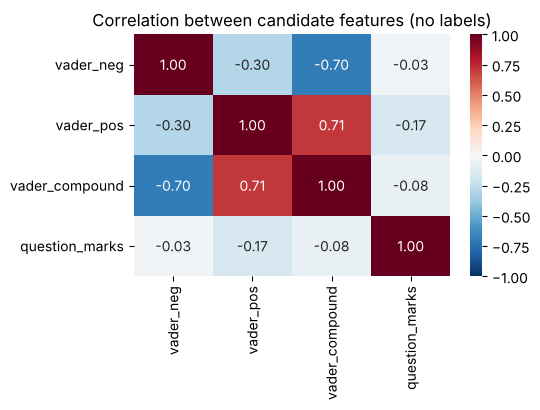

Pairs with |r| > 0.7: [('vader_neg', 'vader_compound', np.float64(-0.7)), ('vader_pos', 'vader_compound', np.float64(0.71))]


In [13]:
# (1) Coverage: share of tweets where each candidate is non-zero
print((candidates != 0).mean().round(3).to_frame('share non-zero').T)
# (2) Which words does VADER score most often in these tweets? (sanity check of a general-purpose lexicon)
lex = vader.lexicon
words = df['text_light'].str.lower().str.findall(r"[a-z']+")
hits = Counter(w for ws in words for w in ws if w in lex)
print('\nMost frequent POSITIVE VADER words:', [(w, n) for w, n in hits.most_common(400) if lex[w] > 0][:15])
print('Most frequent NEGATIVE VADER words:', [(w, n) for w, n in hits.most_common(400) if lex[w] < 0][:15])
# (3) Redundancy
corr = candidates.corr()
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation between candidate features (no labels)'); plt.tight_layout(); plt.show()
print('Pairs with |r| > 0.7:', [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr)
                                for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) > 0.7])

**Screening decisions (label-free):**
- **Coverage:** VADER finds negative wording in 48% of tweets and positive wording in 53%; 25% of tweets contain a "?". All three cues are frequent enough to shape clusters.
- **Lexicon fit:** VADER's most frequent matches look right for airline tweets: positive *thanks, thank, great, good, love, best*; negative *no, cancelled, delayed, delay, worst, lost, stuck, rude*. Being general-purpose, it also has quirks. The airline name *united*, and request words such as *help, please, want*, count as positive. We **do not edit** the lexicon, because hand-editing it would bring in our own judgement; the quirks are reported as a limitation.
- **Redundancy:** `vader_compound` correlates −0.70 with `vader_neg` and +0.71 with `vader_pos`. It is essentially a combination of the two, so it is **dropped**. `question_marks` is only weakly related to the VADER scores, so it adds a separate dimension.

**Final features (3):** `vader_neg`, `vader_pos`, `question_marks`, one for each tweet type in the README. They are standardised in Section 5.

In [14]:
FEATURES = ['vader_neg', 'vader_pos', 'question_marks']
feat = candidates[FEATURES].copy()
feat.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
vader_neg,14639.0,0.09,0.12,0.0,0.0,0.00,0.15,1.0
vader_pos,14639.0,0.13,0.18,0.0,0.0,0.08,0.21,1.0
question_marks,14639.0,0.31,0.59,0.0,0.0,0.00,1.00,6.0


### 4.3 MiniLM sentence embeddings (general meaning)
A **sentence embedding** is *learned*: a pre-trained transformer reads the whole tweet and outputs one dense vector. It reads **word order and context** ("not good" ≠ "good") and knows **synonyms** ("late", "delayed"). `all-MiniLM-L6-v2` (22M parameters, 384 dims) was trained for general sentence similarity, not on this dataset or its labels. Input: `text_light`. `normalize_embeddings=True` gives every vector length 1, so Euclidean K-Means behaves like cosine distance and no StandardScaler is needed.


> **Definitions used here** (see *List of definitions_v16.csv*): **B4** Sentence embedding · **B1** L2 normalisation · **D6** Embedding cache

In [15]:
def load_or_encode(cache, model_name, prompt=None):
    '''Load a cached embedding matrix, or encode the tweets once (Colab GPU recommended) and cache it.'''
    if os.path.exists(cache):
        return np.load(cache).astype(np.float32)
    from sentence_transformers import SentenceTransformer
    import torch
    gpu = torch.cuda.is_available()
    m = SentenceTransformer(model_name, device='cuda' if gpu else 'cpu')
    E = m.encode(df['text_light'].tolist(), prompt=prompt, batch_size=64,
                 normalize_embeddings=True, show_progress_bar=True)
    np.save(cache, E)
    return E.astype(np.float32)

X_minilm = load_or_encode('tweet_embeddings_minilm.npy', 'all-MiniLM-L6-v2')
print('MiniLM matrix:', X_minilm.shape, '| vector norms ≈', np.linalg.norm(X_minilm, axis=1).mean().round(3))

MiniLM matrix: (14639, 384) | vector norms ≈ 1.0


### 4.4 The three representations side by side

In [16]:
summary = pd.DataFrame({
    'dimensions':        [X_tfidf.shape[1], feat.shape[1], X_minilm.shape[1]],
    'share non-zero':    [X_tfidf.nnz / np.prod(X_tfidf.shape), (feat.values != 0).mean(), 1.0],
    'readable columns?': ['yes (words)', 'yes (features)', 'no'],
    'built from':        ['this dataset (word counts)', 'published lexicon (VADER) + "?" count', 'pre-trained transformer'],
    'scaling':           ['L2 rows (cosine)', 'StandardScaler (z-scores)', 'L2 (cosine)'],
}, index=REPS)
summary.round(4)

,dimensions,share non-zero,readable columns?,built from,scaling
TF-IDF,16511,0.0013,yes (words),this dataset (word counts),L2 rows (cosine)
Lexicon features,3,0.4229,yes (features),"published lexicon (VADER) + ""?"" count",StandardScaler (z-scores)
MiniLM,384,1.0000,no,pre-trained transformer,L2 (cosine)


## 5. Distance and scaling: how each representation "sees" three tweets
K-Means and Ward use **Euclidean distance** $d(\mathbf{x},\mathbf{c})=\sqrt{\sum_j (x_j-c_j)^2}$, and the GMM uses distances scaled by each cluster's covariance. So the representation and its scaling decide which tweets count as close.


> **Definitions used here** (see *List of definitions_v16.csv*): **D3** Euclidean distance · **D2** Cosine distance · **B1** L2 normalisation · **B5** Standardisation

In [17]:
# Three example tweets: a complaint, a frustrated question and a thank-you
idx = [df.index[df.text.str.contains('lost my bag', case=False)][0],
       df.index[df.text.str.contains('what time', case=False)][0],
       df.index[df.text.str.contains('thank you so much', case=False)][0]]
for i in idx: print(i, '|', df.text[i])
feat.loc[idx]

68 | @VirginAmerica everything was fine until you lost my bag
642 | @united what time? Who can I call. I need my skis. I will go to the airport and get them. No more faith in United.
2644 | @united Thank you so much for your help with my birthday trip! Tickets are confirmed! :-)


,vader_neg,vader_pos,question_marks
68,0.228,0.178,0
642,0.167,0.106,1
2644,0.000,0.403,0


### 5.1 Raw lexicon features: the count feature dominates

In [18]:
D_raw = pairwise_distances(feat.loc[idx], metric='euclidean')
print('Raw Euclidean distances:'); print(pd.DataFrame(D_raw, idx, idx).round(2))
print('\nStandard deviation of each feature:', feat.std().round(2).to_dict())
def shares(F):
    '''share of the squared distance contributed by each feature, for two pairs of example tweets'''
    out = {}
    for name, (a, b) in {'complaint vs question': (0, 1), 'complaint vs thank-you': (0, 2)}.items():
        d2 = (F.loc[idx[a]] - F.loc[idx[b]]) ** 2; out[name] = (d2 / d2.sum()).round(2)
    return pd.DataFrame(out)
print('\nShare of squared distance, RAW features:'); print(shares(feat))

Raw Euclidean distances:
      68    642   2644
68    0.00  1.00  0.32
642   1.00  0.00  1.06
2644  0.32  1.06  0.00

Standard deviation of each feature: {'vader_neg': 0.12, 'vader_pos': 0.18, 'question_marks': 0.59}

Share of squared distance, RAW features:
                complaint vs question  complaint vs thank-you
vader_neg                        0.00                    0.51
vader_pos                        0.01                    0.49
question_marks                   0.99                    0.00


### 5.2 Standardisation fixes it
`StandardScaler` gives every feature mean 0 and standard deviation 1, $z=(x-\mu)/\sigma$, so each has an equal say. It is fitted on the features only, never on labels. TF-IDF and the MiniLM embeddings need no StandardScaler: their rows have length 1, and for unit vectors $\lVert a-b\rVert^2 = 2(1-\cos(a,b))$, so Euclidean distance is a monotone function of cosine distance.

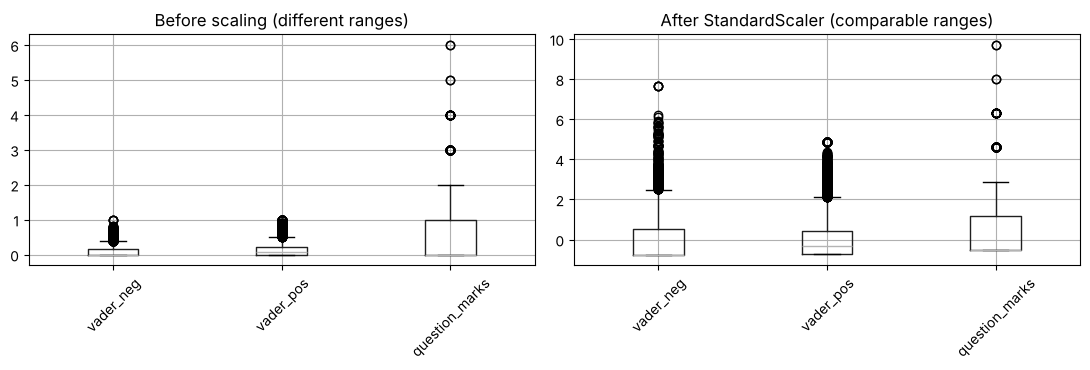

Share of squared distance, SCALED features:
                complaint vs question  complaint vs thank-you
vader_neg                        0.08                     0.7
vader_pos                        0.05                     0.3
question_marks                   0.87                     0.0


In [19]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(feat)              # shape (14639, 3)
X_scaled_df = pd.DataFrame(X_scaled, columns=feat.columns)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
feat.boxplot(ax=ax[0], rot=45);        ax[0].set_title('Before scaling (different ranges)')
X_scaled_df.boxplot(ax=ax[1], rot=45); ax[1].set_title('After StandardScaler (comparable ranges)')
plt.tight_layout(); plt.show()
X_scaled_df.index = feat.index
print('Share of squared distance, SCALED features:'); print(shares(X_scaled_df))

**Reading the distances (our run):**
- **Raw features are on very different scales.** The standard deviations are 0.12 (`vader_neg`), 0.18 (`vader_pos`) and 0.59 (`question_marks`). Between the complaint and the frustrated question, a single "?" makes up **99%** of the squared distance, and the VADER scores barely count.
- **After `StandardScaler`, every feature is measured in standard deviations.** The question mark still dominates that pair (87%), because the two tweets really do differ mainly by the question. But each VADER difference now counts several times more than before.
- **Between the complaint and the thank-you**, which differ in tone, not in "?", the distance comes entirely from VADER: 70% `vader_neg`, 30% `vader_pos`.
- Section 12.3 shows what happens without scaling. K-Means then simply splits the tweets into 0, 1 and 2+ question marks.

### 5.3 The same three tweets in all three representations
For comparability we show **cosine distances** (0 = same direction, 1 = unrelated, 2 = opposite) in every representation; the scaled lexicon features can point in opposite directions, so their values can exceed 1. The ideal sentiment representation puts the complaint and the frustrated question close together and both far from the thank-you.

In [20]:
pair_names = ['complaint vs question', 'complaint vs thank-you', 'question vs thank-you']
pairs_ix = [(0, 1), (0, 2), (1, 2)]
rep_rows = {'TF-IDF': X_tfidf[idx], 'Lexicon features': X_scaled[idx], 'MiniLM': X_minilm[idx]}
dist_tab = pd.DataFrame({r: [pairwise_distances(M, metric='cosine')[a, b] for a, b in pairs_ix]
                         for r, M in rep_rows.items()}, index=pair_names).T
dist_tab.round(3)

,complaint vs question,complaint vs thank-you,question vs thank-you
TF-IDF,0.991,0.981,0.993
Lexicon features,0.935,1.093,1.551
MiniLM,0.784,0.880,0.687


**Reading the example (our run):**
- **TF-IDF:** all distances are 0.98–0.99. The three tweets share almost no words, so to TF-IDF they look equally unrelated.
- **Lexicon features:** this is the only representation that behaves as intended. The complaint and the frustrated question are closest (0.94), and the question is farthest from the thank-you (1.55).
- **MiniLM:** it places the question closest to the **thank-you** (0.69), not to the complaint (0.78). It sees "two short messages to an airline", not their opposite feelings.

## 6. Three clustering algorithms
| | **K-Means** | **GMM** (Gaussian Mixture Model) | **Ward agglomerative** |
|---|---|---|---|
| Idea | k centroids; each tweet joins the nearest | k overlapping Gaussian "bells", each with its own mean, shape (covariance) and size (weight) | Start with every tweet alone; repeatedly merge the two clusters whose merge increases within-cluster variance least |
| Assignment | Hard (one cluster) | **Soft** (probabilities that sum to 1) | Hard |
| Cluster shape | Round, similar size | Ellipses of any size | Compact (same objective as K-Means), but built bottom-up |
| Fitting | Lloyd iterations; `k-means++`, `n_init=20` | EM (E-step = soft assign, M-step = update); `n_init=5` | Deterministic merge tree (dendrogram) |
| New tweets | `predict()` | `predict()` / `predict_proba()` | No `predict()`: assign to nearest cluster mean |
| Cost | Fast | Medium (covariances) | Needs all ~107 million pairwise distances |

K-Means is a special case of a GMM (equal round covariances, hard 0/1 assignments), and Ward optimises the same within-cluster variance as K-Means, so comparing the three on the same input isolates the effect of *how* the clusters are built.


> **Definitions used here** (see *List of definitions_v16.csv*): **A4** K-Means · **A5** K-Means from scratch · **A6** k-means++ / n_init · **A3** GMM · **A2** EM · **A7** Agglomerative clustering

### 6.1 K-Means from scratch (to show the algorithm)
1. **Initialise:** pick k random tweets as starting centroids. 2. **Assign:** each tweet to its nearest centroid. 3. **Update:** move each centroid to the mean of its tweets. 4. Repeat until nothing changes (inertia never increases, so it converges, possibly to a local minimum).

From scratch: 14 iterations, final inertia 21592
scikit-learn: 5 iterations, inertia 21386, sizes [7762 3301 3576]
Agreement scratch vs scikit-learn (ARI): 0.419


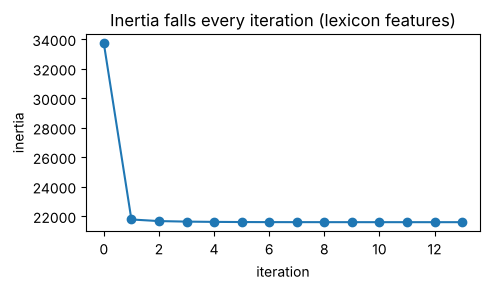

In [21]:
def kmeans_scratch(X, k=3, max_iter=100, seed=SEED):
    rng = np.random.default_rng(seed)
    centroids = X[rng.choice(len(X), k, replace=False)]                       # step 1
    history = []
    for it in range(max_iter):
        dist = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)  # (n, k)
        labels = dist.argmin(axis=1)                                           # step 2
        new_centroids = np.array([X[labels == j].mean(axis=0) for j in range(k)])  # step 3
        history.append((dist[np.arange(len(X)), labels] ** 2).sum())
        if np.allclose(new_centroids, centroids): break                        # step 4
        centroids = new_centroids
    return labels, centroids, history

labels_scratch, cent_scratch, hist = kmeans_scratch(X_scaled)
km_check = KMeans(n_clusters=3, init='k-means++', n_init=20, random_state=SEED).fit(X_scaled)
print(f'From scratch: {len(hist)} iterations, final inertia {hist[-1]:.0f}')
print(f'scikit-learn: {km_check.n_iter_} iterations, inertia {km_check.inertia_:.0f}, sizes {np.bincount(km_check.labels_)}')
print('Agreement scratch vs scikit-learn (ARI):', round(adjusted_rand_score(labels_scratch, km_check.labels_), 3))
plt.figure(figsize=(5, 3)); plt.plot(hist, 'o-'); plt.title('Inertia falls every iteration (lexicon features)')
plt.xlabel('iteration'); plt.ylabel('inertia'); plt.tight_layout(); plt.show()

**Reading the check (our run):**
- The from-scratch version converges in 14 iterations, and its inertia falls every iteration.
- It stops at inertia **21,592**, while scikit-learn reaches **21,386**. The two agree only at ARI 0.419.
- Our simple version starts from k random tweets once, and here it got stuck in a **worse local minimum**.
- This is exactly why the reported model uses `init='k-means++'` (spread-out starting centroids) and `n_init=20` (20 starts, keep the lowest inertia). With these settings the result is identical across seeds (Section 13.4).

### 6.2 Which input does each algorithm get?
K-Means can work on any representation, including the sparse 16,511-column TF-IDF matrix. The GMM and Ward need a bit more care:
- **GMM** estimates a covariance matrix per cluster. A full covariance on MiniLM's 384 dimensions would need about 74,000 parameters per cluster, which is unstable with 14,639 tweets (the *curse of dimensionality*). So the GMM gets **50 dimensions**: PCA for the dense embeddings, and **truncated SVD (LSA)** for the sparse TF-IDF matrix (PCA cannot centre a sparse matrix).
- **Ward** needs dense vectors and all pairwise distances. It uses the **same input as K-Means** for the lexicon features and the embeddings (so K-Means vs Ward is a like-for-like comparison), and the 50-d LSA version of TF-IDF.
- The lexicon features are already 3-dimensional, so all three algorithms use the same `X_scaled`.

| Representation | K-Means input | GMM input | Ward input |
|---|---|---|---|
| TF-IDF | sparse TF-IDF (16,511-d, L2) | LSA-50 (L2) | LSA-50 (L2) |
| Lexicon features | `X_scaled` (3-d) | `X_scaled` | `X_scaled` |
| MiniLM | 384-d (L2) | PCA-50 | 384-d (L2) |


> **Definitions used here** (see *List of definitions_v16.csv*): **B11** Truncated SVD / LSA · **B3** PCA · **D8** Curse of dimensionality

In [22]:
svd50 = TruncatedSVD(n_components=50, random_state=SEED).fit(X_tfidf)
X_tfidf_lsa = normalize(svd50.transform(X_tfidf))                 # LSA-50, rows L2-normalised
pca_minilm = PCA(n_components=50, random_state=SEED).fit(X_minilm); X_minilm50 = pca_minilm.transform(X_minilm)
print('Variance kept by 50 components:  TF-IDF (SVD) %.1f%% | MiniLM %.1f%%' % (
      100 * svd50.explained_variance_ratio_.sum(), 100 * pca_minilm.explained_variance_ratio_.sum()))

INPUTS = {   # representation -> {algorithm: matrix}
    'TF-IDF':           {'K-Means': X_tfidf,  'GMM': X_tfidf_lsa, 'Ward': X_tfidf_lsa},
    'Lexicon features': {'K-Means': X_scaled, 'GMM': X_scaled,    'Ward': X_scaled},
    'MiniLM':           {'K-Means': X_minilm, 'GMM': X_minilm50,  'Ward': X_minilm},
}

Variance kept by 50 components:  TF-IDF (SVD) 10.6% | MiniLM 55.6%


## 7. Label-free model selection
All choices in this section use **no labels**: k from inertia and silhouette, the GMM covariance type from BIC, and the dendrograms to see how natural three clusters are.


> **Definitions used here** (see *List of definitions_v16.csv*): **C5** Inertia / elbow · **C10** Silhouette · **C2** BIC · **A7** Agglomerative clustering

### 7.1 How many clusters? Elbow and silhouette for each representation

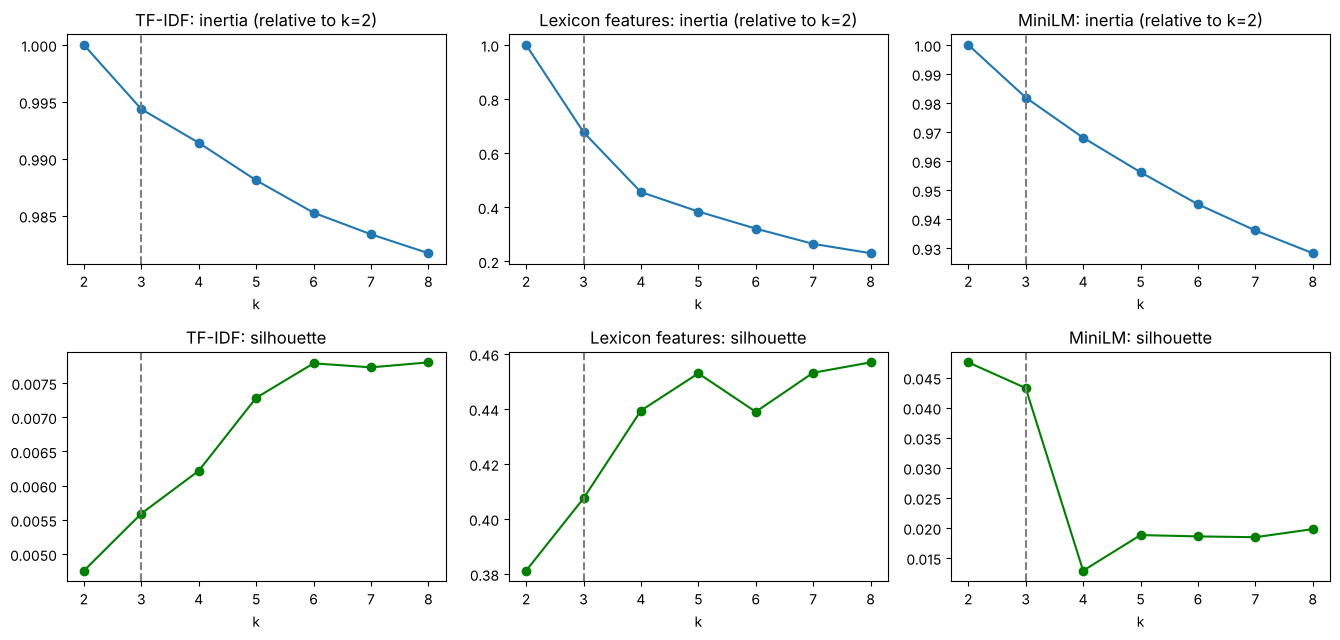

,TF-IDF,Lexicon features,MiniLM
k,,,
2,0.005,0.381,0.048
3,0.006,0.407,0.043
4,0.006,0.439,0.013
5,0.007,0.453,0.019
6,0.008,0.439,0.019
7,0.008,0.453,0.018
8,0.008,0.457,0.020


In [23]:
ks = range(2, 9)
elbow = {}
for rep in REPS:
    X = INPUTS[rep]['K-Means']
    inert, sils = [], []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
        inert.append(km.inertia_)
        sils.append(silhouette_score(X, km.labels_, sample_size=5000, random_state=SEED))
    elbow[rep] = (np.array(inert), np.array(sils))

fig, ax = plt.subplots(2, len(REPS), figsize=(4.5 * len(REPS), 6.5))
for j, rep in enumerate(REPS):
    inert, sils = elbow[rep]
    ax[0, j].plot(list(ks), inert / inert[0], 'o-'); ax[0, j].set_title(f'{rep}: inertia (relative to k=2)')
    ax[1, j].plot(list(ks), sils, 'o-', color='green'); ax[1, j].set_title(f'{rep}: silhouette')
    for a in ax[:, j]: a.axvline(3, ls='--', c='grey'); a.set_xlabel('k')
plt.tight_layout(); plt.show()
pd.DataFrame({rep: elbow[rep][1] for rep in REPS}, index=list(ks)).round(3).rename_axis('k')

**Reading the curves (our run):**
- **No representation has a peak at k = 3.** The lexicon features' silhouette rises steadily, from 0.381 at k = 2 to 0.407 at k = 3 and 0.457 at k = 8. MiniLM's is highest at k = 2 (0.048). TF-IDF is close to 0 for every k (0.006), so it has no compact cluster structure at all.
- None of the inertia curves has a sharp elbow. Sentiment is a spectrum, not three separate blobs.
- We keep **k = 3** because the task requires it, and say honestly that the data does not single it out.

### 7.2 GMM covariance type, chosen by BIC
`covariance_type`: `spherical` (round), `diag` (axis-aligned ellipses), `tied` (one shared ellipse) or `full` (any ellipse per cluster). **BIC** = fit minus a penalty for extra parameters (lower is better); it needs no labels.

In [24]:
COV_TYPES = ['spherical', 'diag', 'tied', 'full']
gmm_fits, bic_tab = {}, {}
for rep in REPS:
    X = INPUTS[rep]['GMM']
    for cov in COV_TYPES:
        g = GaussianMixture(n_components=3, covariance_type=cov, n_init=3, random_state=SEED).fit(X)
        gmm_fits[(rep, cov)] = g
        bic_tab[(rep, cov)] = g.bic(X)
bic_df = pd.Series(bic_tab).unstack()[COV_TYPES].loc[REPS]
best_cov = bic_df.idxmin(axis=1).to_dict()
print('BIC (lower = better):'); print(bic_df.round(0))
print('\nChosen covariance type per representation:', best_cov)

BIC (lower = better):
                  spherical       diag       tied       full
TF-IDF            -923001.0 -1012056.0  -943149.0 -1192968.0
Lexicon features    47471.0   -98409.0   110464.0   -98878.0
MiniLM           -1420619.0 -1533992.0 -1516851.0 -1585223.0

Chosen covariance type per representation: {'TF-IDF': 'full', 'Lexicon features': 'full', 'MiniLM': 'full'}


### 7.3 Ward dendrograms: do three natural groups exist?

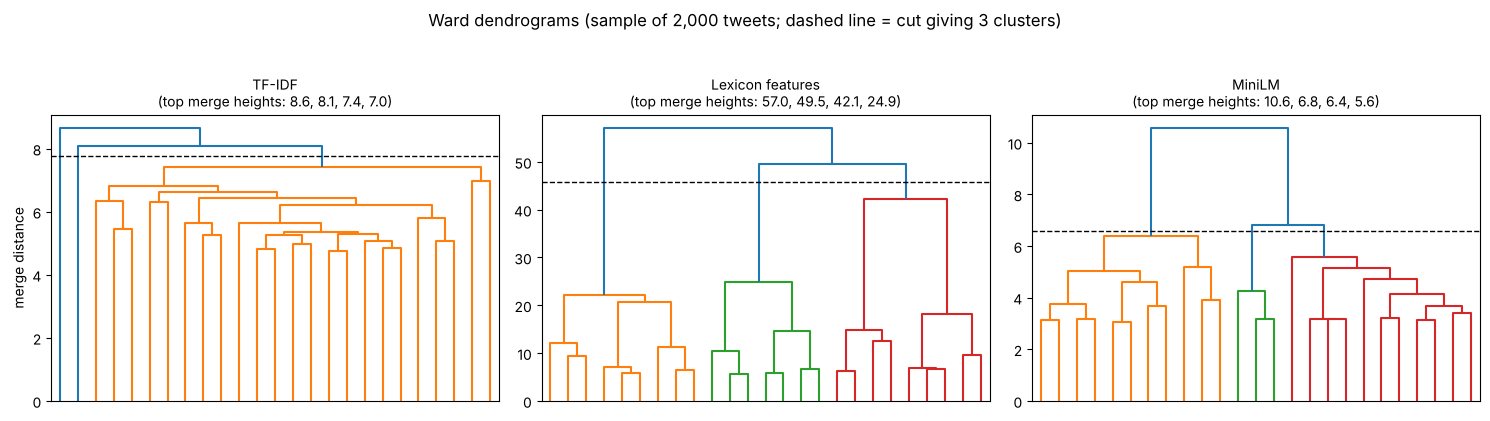

In [25]:
rng = np.random.default_rng(SEED)
sample = rng.choice(len(df), 2000, replace=False)              # the full tree has 14,639 leaves
fig, axes = plt.subplots(1, len(REPS), figsize=(5 * len(REPS), 4))
for ax, rep in zip(axes, REPS):
    Xw = INPUTS[rep]['Ward']
    Z = linkage(Xw[sample], method='ward')
    cut = (Z[-3, 2] + Z[-2, 2]) / 2                            # between the last two merges -> 3 clusters
    dendrogram(Z, truncate_mode='lastp', p=25, color_threshold=cut, no_labels=True, ax=ax)
    ax.axhline(cut, color='black', ls='--', lw=1)
    ax.set_title(f'{rep}\n(top merge heights: ' + ', '.join(f'{h:.1f}' for h in Z[-4:, 2][::-1]) + ')', fontsize=10)
axes[0].set_ylabel('merge distance')
plt.suptitle('Ward dendrograms (sample of 2,000 tweets; dashed line = cut giving 3 clusters)', y=1.04)
plt.tight_layout(); plt.show()

**Reading the dendrograms (our run):**
- **TF-IDF:** the top merges split off two small groups before the large mass. This foreshadows the 13,607 / 490 / 542 split in Section 8.
- **Lexicon features:** the clearest tree. The top merges are at 57.0 and 49.5, the cut for 3 clusters falls between 49.5 and 42.1, and there is a large drop to 24.9 below that. So the lexicon features contain a few well-separated groups (3 or 4).
- **MiniLM:** a clear top split (10.6), then two almost equal merges (6.8 and 6.4). The third cluster is a weak choice.

The BIC choices in 7.2 are **full** covariance for all three representations. For the lexicon features, full (−98,878) only narrowly beats diag (−98,409). The 50 components keep 10.6% of the TF-IDF variance (word counts are very spread out) and 55.6% of MiniLM's.

## 8. Fit the 9 models (TF-IDF + K-Means is the baseline)
Each model uses k = 3, the inputs from Section 6.2, seed 42, `n_init=20` for K-Means, the BIC-chosen covariance and `n_init=5` for the GMM, and Ward linkage.

**Baseline: TF-IDF + K-Means.** Word counts clustered with K-Means are the standard, off-the-shelf way to cluster text, so it is the natural reference point: the other eight models are judged by how much they improve on it.


> **Definitions used here** (see *List of definitions_v16.csv*): **A1** Baseline: TF-IDF + K-Means · **A4** K-Means · **A3** GMM · **A7** Agglomerative clustering

In [26]:
labels, models, probas, fit_time = {}, {}, {}, {}
for rep in REPS:
    for algo in ALGOS:
        X = INPUTS[rep][algo]
        t0 = time.time()
        if algo == 'K-Means':
            m = KMeans(n_clusters=3, init='k-means++', n_init=20, random_state=SEED).fit(X)
            lab = m.labels_
        elif algo == 'GMM':
            m = GaussianMixture(n_components=3, covariance_type=best_cov[rep], n_init=5, random_state=SEED).fit(X)
            lab = m.predict(X); probas[rep] = m.predict_proba(X)
        else:
            m = AgglomerativeClustering(n_clusters=3, linkage='ward').fit(X)
            lab = m.labels_
        labels[(rep, algo)], models[(rep, algo)], fit_time[(rep, algo)] = lab, m, time.time() - t0
        print(f'{rep:17s} {algo:8s} sizes {np.bincount(lab)}  ({fit_time[(rep, algo)]:.1f}s)')

TF-IDF            K-Means  sizes [  208   362 14069]  (1.1s)


TF-IDF            GMM      sizes [3714 3529 7396]  (5.5s)


TF-IDF            Ward     sizes [13607   490   542]  (19.6s)
Lexicon features  K-Means  sizes [7762 3301 3576]  (0.1s)


Lexicon features  GMM      sizes [5318 5647 3674]  (0.3s)


Lexicon features  Ward     sizes [8867 3668 2104]  (5.2s)


MiniLM            K-Means  sizes [3547 4437 6655]  (1.7s)


MiniLM            GMM      sizes [5770 2595 6274]  (3.6s)


MiniLM            Ward     sizes [4987 8734  918]  (37.3s)


## 9. Evaluation against the true labels (labels used only from here on)
### 9.1 First look at the labels
Everything below uses `airline_sentiment` or `sentiment_confidence`, so it comes **after** clustering. Nothing here was used to build the representations or choose the models.


> **Definitions used here** (see *List of definitions_v16.csv*): **D1** Confounder · **C3** Contingency table · **C1** ARI

Class balance:
airline_sentiment
negative    0.627
neutral     0.212
positive    0.161
Name: proportion, dtype: float64 

                    mean  share_conf_1  share_below_0_6
airline_sentiment                                      
negative           0.933         0.804            0.007
neutral            0.823         0.500            0.033
positive           0.872         0.641            0.030


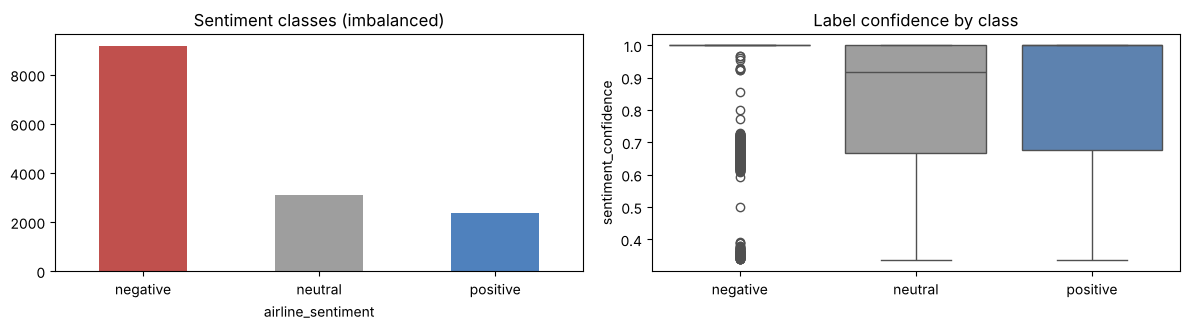

In [27]:
y = df['airline_sentiment'].values              # labels used ONLY from here on
CLASSES = np.array(['negative', 'neutral', 'positive'])
print('Class balance:'); print(df['airline_sentiment'].value_counts(normalize=True).round(3), '\n')
print(df.groupby('airline_sentiment')['sentiment_confidence'].agg(
    mean='mean', share_conf_1=lambda s: (s == 1).mean(), share_below_0_6=lambda s: (s < 0.6).mean()).round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
df['airline_sentiment'].value_counts().reindex(CLASSES).plot.bar(ax=ax[0], color=list(SENT_COLORS.values()), rot=0)
ax[0].set_title('Sentiment classes (imbalanced)')
sns.boxplot(data=df, x='airline_sentiment', y='sentiment_confidence', order=list(CLASSES),
            palette=list(SENT_COLORS.values()), ax=ax[1]); ax[1].set_title('Label confidence by class'); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()

In [28]:
# Label noise: duplicated texts with CONFLICTING labels
dup_groups = df[df['text'].duplicated(keep=False)].groupby('text')
conflict = dup_groups['airline_sentiment'].nunique().gt(1)
print('Duplicated texts with conflicting labels:', conflict.sum())
# Airline as a confounder
air = pd.crosstab(df['airline'], df['airline_sentiment'])
air_pct = (air.div(air.sum(axis=1), axis=0) * 100).round(1); air_pct['n_tweets'] = air.sum(axis=1)
print(air_pct[air_pct['n_tweets'] >= 30].sort_values('negative', ascending=False))
by_airline = df['airline'].isin(['United', 'US Airways', 'American']).astype(int).values
print('\nARI of grouping tweets by airline only:', round(adjusted_rand_score(y, by_airline), 3))

Duplicated texts with conflicting labels: 25
airline_sentiment  negative  neutral  positive  n_tweets
airline                                                 
US Airways             77.7     13.1       9.2      2913
American               71.0     16.8      12.2      2759
United                 68.9     18.2      12.9      3821
Southwest              49.0     27.4      23.5      2421
JetBlue                43.0     32.6      24.5      2218
Virgin America         36.0     34.0      30.0       503



ARI of grouping tweets by airline only: 0.109


In [29]:
# Text cues and lexicon features by class (checked only now, after clustering)
print(elements.groupby(df['airline_sentiment']).mean().round(2).T, '\n')
print(feat.groupby(y).mean().T.round(2))
# Words most distinctive of each class (usage rate in the class vs the other two; words in >= 30 tweets)
rows_w = []
for s in CLASSES:
    m = (y == s)
    in_c, out_c = np.asarray((counts[m] > 0).sum(axis=0)).ravel(), np.asarray((counts[~m] > 0).sum(axis=0)).ravel()
    ratio = ((in_c + 1) / m.sum()) / ((out_c + 1) / (~m).sum())
    rows_w.append(pd.Series(vocab_cv[np.argsort(np.where(df_freq >= 30, ratio, 0))[::-1][:12]], name=s))
pd.concat(rows_w, axis=1)

airline_sentiment  negative  neutral  positive
has "!"                0.17     0.14      0.51
has "?"                0.26     0.39      0.04
has ALL-CAPS word      0.26     0.30      0.25
has negation           0.44     0.14      0.11
has hashtag            0.17     0.13      0.19
has URL                0.05     0.16      0.10
has emoji              0.02     0.04      0.08
has emoticon           0.01     0.02      0.07
repeated letters       0.01     0.01      0.01 

                negative  neutral  positive
vader_neg           0.12     0.04      0.02
vader_pos           0.07     0.13      0.36
question_marks      0.33     0.44      0.05


,negative,neutral,positive
0,worst,wall,kudos
1,ridiculous,ceo,rock
2,unacceptable,fleek,awesome
3,worse,fleet's,amazing
4,fail,hi,thank
5,communication,destinationdragons,great
6,automated,rt,haha
7,rude,atlanta,quick
8,answers,companion,thanks
9,lack,following,best


**What the labels show (all after clustering):**
- **Imbalance:** 62.7% negative, 21.2% neutral, 16.1% positive. A single cluster already matches 63% of tweets, so purity and accuracy are misleading.
- **Label confidence:** negative labels are the most certain (80% have confidence = 1), then positive (64%), then neutral (50%).
- **Label noise:** 25 duplicated texts carry conflicting labels.
- **Airline is a confounder:** US Airways is 78% negative but Virgin America only 36%. Grouping by airline alone gives ARI 0.109.
- **Neutral has no sentiment vocabulary of its own.** Its most distinctive words are greetings, retweets and campaign hashtags (hi, rt, fleek, destinationdragons). Negative (worst, ridiculous, rude) and positive (kudos, awesome, thank) have clear sentiment words.
- **The three features point the right way:**
  - `vader_neg` averages 0.12 in negative tweets against 0.02–0.04 in the others;
  - `vader_pos` averages 0.36 in positive tweets against 0.07–0.13;
  - `question_marks` is highest in neutral tweets (0.44) and lowest in positive ones (0.05).

  This matches the README's description of the three tweet types.

### 9.2 Metrics
Cluster numbers are arbitrary, so we use metrics designed for clusterings:

| Role | Metric | Why |
|---|---|---|
| **Core (primary)** | **Macro-F1** after Hungarian matching | Each cluster is mapped to one class; all three classes count equally, so a model cannot score well by ignoring neutral or positive (63% of tweets are negative). |
| **Core** | **ARI** | Chance-corrected agreement (0 = chance, 1 = perfect). Can favour a model that isolates the big negative class. |
| **Core** | **NMI** | Information-based check of ARI. |
| **Core (explains the numbers)** | **Contingency table** | *Which* sentiments end up in which cluster. |
| Supporting | Purity, matched accuracy | Inflated by imbalance: putting every tweet into one cluster would already score 0.627. |
| Supporting | Silhouette | Separation without labels; only comparable within one representation. |
| Model selection only | Inertia, BIC | Used without labels in Section 7. |


> **Definitions used here** (see *List of definitions_v16.csv*): **C6** Macro-F1 · **C4** Hungarian matching · **C1** ARI · **C8** NMI · **C9** Purity · **C7** Matched accuracy · **C10** Silhouette

In [30]:
def map_clusters(lab, y):
    '''Hungarian matching: give each cluster the class that maximises total agreement.'''
    ct = pd.crosstab(lab, y).reindex(columns=CLASSES, fill_value=0)
    r, c = linear_sum_assignment(-ct.values)
    mapping = {ct.index[i]: CLASSES[j] for i, j in zip(r, c)}
    return np.array([mapping.get(l, 'negative') for l in lab])

def evaluate(lab, X=None, y=None):
    y = df['airline_sentiment'].values if y is None else y
    ct = pd.crosstab(lab, y); y_pred = map_clusters(lab, y)
    return {'ARI': adjusted_rand_score(y, lab), 'NMI': normalized_mutual_info_score(y, lab),
            'purity': ct.max(axis=1).sum() / len(y), 'matched_acc': (y_pred == y).mean(),
            'macro_F1': f1_score(y, y_pred, average='macro'),
            'silhouette': silhouette_score(X, lab, sample_size=5000, random_state=SEED)
                          if X is not None and len(set(lab)) > 1 else np.nan,
            'sizes': ' / '.join(map(str, np.bincount(lab)))}

rows = []
for rep in REPS:
    for algo in ALGOS:
        rows.append({'representation': rep, 'algorithm': algo, 'role': 'baseline' if (rep, algo) == BASELINE else '',
                     **evaluate(labels[(rep, algo)], INPUTS[rep][algo])})
results = pd.DataFrame(rows)
base = results[results.role == 'baseline'].iloc[0]
results['F1 vs baseline'] = results['macro_F1'] - base['macro_F1']
results['ARI vs baseline'] = results['ARI'] - base['ARI']
results.round(3)

,representation,algorithm,role,ARI,NMI,purity,matched_acc,macro_F1,silhouette,sizes,F1 vs baseline,ARI vs baseline
0,TF-IDF,K-Means,baseline,0.075,0.070,0.652,0.652,0.359,0.006,208 / 362 / 14069,0.000,0.000
1,TF-IDF,GMM,,0.083,0.047,0.627,0.507,0.431,0.014,3714 / 3529 / 7396,0.072,0.008
2,TF-IDF,Ward,,0.041,0.059,0.648,0.621,0.347,0.031,13607 / 490 / 542,-0.012,-0.033
3,Lexicon features,K-Means,,0.195,0.165,0.694,0.612,0.563,0.407,7762 / 3301 / 3576,0.204,0.120
4,Lexicon features,GMM,,0.095,0.127,0.627,0.524,0.486,0.368,5318 / 5647 / 3674,0.127,0.020
5,Lexicon features,Ward,,0.182,0.157,0.701,0.620,0.565,0.406,8867 / 3668 / 2104,0.206,0.107
6,MiniLM,K-Means,,0.079,0.068,0.627,0.461,0.391,0.043,3547 / 4437 / 6655,0.032,0.004
7,MiniLM,GMM,,0.110,0.088,0.668,0.456,0.437,0.031,5770 / 2595 / 6274,0.078,0.036
8,MiniLM,Ward,,0.031,0.029,0.627,0.493,0.345,0.015,4987 / 8734 / 918,-0.014,-0.044


### 9.3 The 3 × 3 grid at a glance

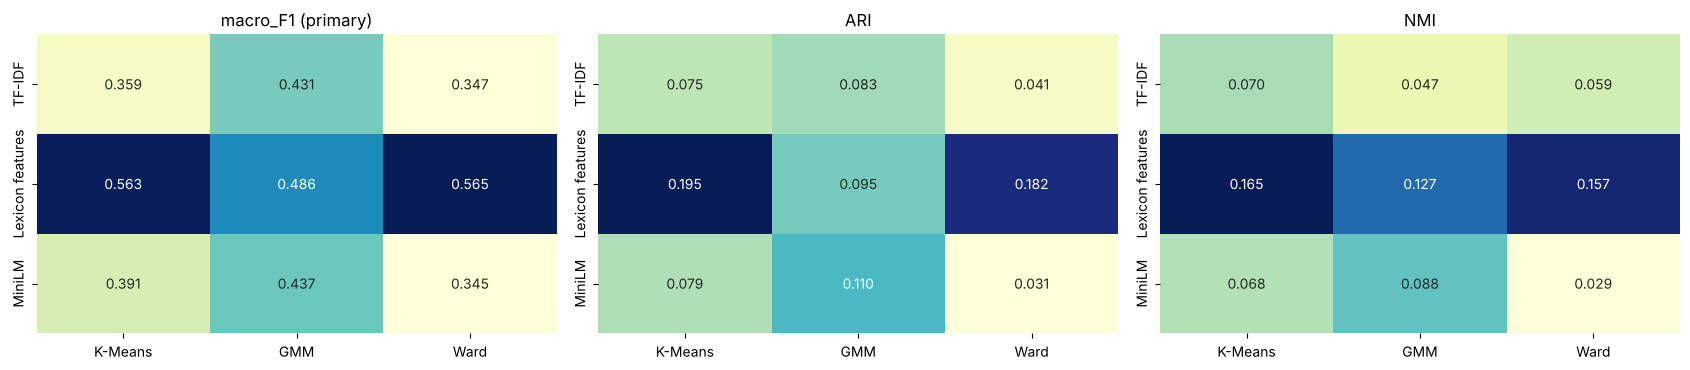

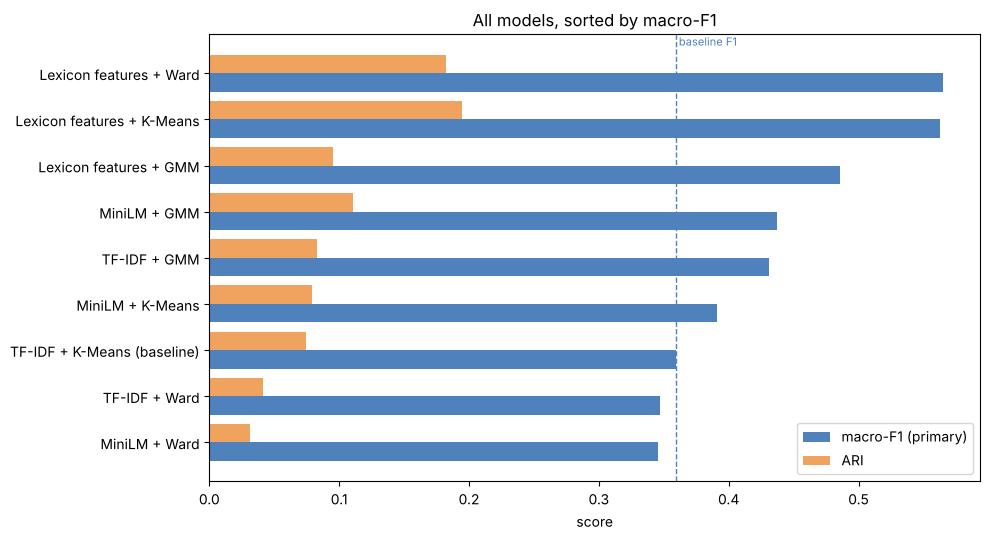

In [31]:
grid = results.set_index(['representation', 'algorithm'])
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for ax, met in zip(axes, ['macro_F1', 'ARI', 'NMI']):
    sns.heatmap(grid[met].unstack()[ALGOS].loc[REPS], annot=True, fmt='.3f', cmap='YlGnBu', ax=ax, cbar=False)
    ax.set_title(met + (' (primary)' if met == 'macro_F1' else '')); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

plot_df = results.copy()
plot_df['model'] = [mname(r, a) for r, a in zip(plot_df.representation, plot_df.algorithm)]
plot_df = plot_df.sort_values('macro_F1')
fig, ax = plt.subplots(figsize=(10, 5.5))
yy = np.arange(len(plot_df))
ax.barh(yy - 0.2, plot_df['macro_F1'], 0.4, label='macro-F1 (primary)', color='#4f81bd')
ax.barh(yy + 0.2, plot_df['ARI'], 0.4, label='ARI', color='#f0a35e')
ax.set_yticks(yy); ax.set_yticklabels(plot_df['model']); ax.legend(loc='lower right')
ax.axvline(base['macro_F1'], color='#4f81bd', ls='--', lw=1); ax.text(base['macro_F1'], len(plot_df) - 0.4, ' baseline F1', color='#4f81bd', fontsize=8)
ax.set_title('All models, sorted by macro-F1'); ax.set_xlabel('score'); plt.tight_layout(); plt.show()

**Reading the grid (our run, seed 42):**

| Representation | K-Means F1 / ARI | GMM F1 / ARI | Ward F1 / ARI |
|---|---|---|---|
| TF-IDF | 0.359 / 0.075 *(baseline)* | 0.431 / 0.083 | 0.347 / 0.041 |
| **Lexicon features** | **0.563 / 0.195** | 0.486 / 0.095 | **0.565** / 0.182 |
| MiniLM | 0.391 / 0.079 | 0.437 / 0.110 | 0.345 / 0.031 |

- **Against the baseline (TF-IDF + K-Means: F1 0.359, ARI 0.075):**
  - Six of the eight other models beat it on both metrics. Only TF-IDF + Ward and MiniLM + Ward fall below it.
  - Lexicon features + K-Means improves macro-F1 by **+0.204** and ARI by **+0.120**.
  - The baseline's F1 looks respectable only because K-Means puts 96% of tweets into one cluster (14,069 of 14,639). Its ARI shows how little sentiment structure it finds.
- **The lexicon features win with every algorithm.** Their weakest model (GMM, F1 0.486) still beats the best TF-IDF or MiniLM model (0.437).
- **Recommended model: lexicon features + K-Means.**
  - Ward is level on macro-F1 (0.565 vs 0.563, a difference of 0.002).
  - But K-Means has the highest ARI (0.195) and NMI (0.165) of all nine models.
  - It is perfectly stable across seeds, whereas Ward varies by ±0.053 on subsamples (Section 13.4).
  - It can assign new tweets with `predict()`.

## 10. Visualising the clusters against the true sentiment
Three complementary pictures: (1) **composition bars** – each bar is a cluster, its width is the cluster size and its colours are the true sentiments; (2) **contingency heat-maps** in row %; (3) **t-SNE maps** – a 2-D picture of each representation coloured by true sentiment and by each algorithm's clusters.


> **Definitions used here** (see *List of definitions_v16.csv*): **C3** Contingency table · **B12** t-SNE · **B3** PCA

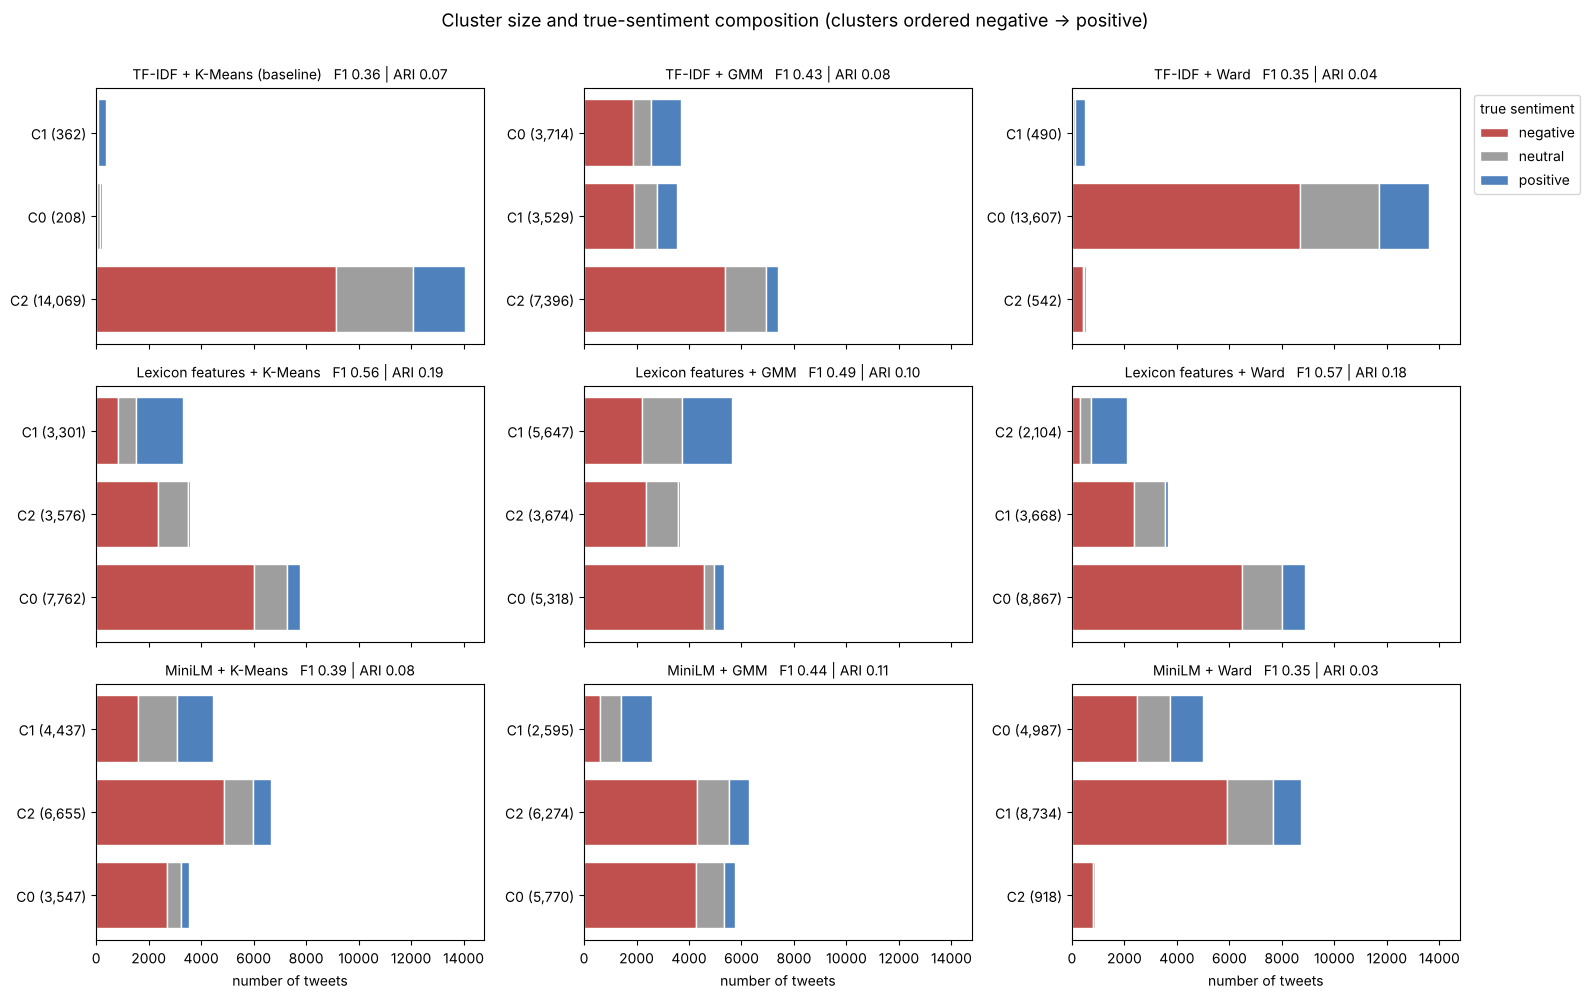

In [32]:
def order_clusters(lab):
    '''Order clusters from most negative to most positive (for readable plots only).'''
    comp = pd.crosstab(lab, y, normalize='index').reindex(columns=CLASSES, fill_value=0)
    return list((comp['positive'] - comp['negative']).sort_values().index)

fig, axes = plt.subplots(len(REPS), 3, figsize=(16, 3.3 * len(REPS)), sharex=True)
for i, rep in enumerate(REPS):
    for j, algo in enumerate(ALGOS):
        ax = axes[i, j]; lab = labels[(rep, algo)]
        ct = pd.crosstab(lab, y).reindex(columns=CLASSES, fill_value=0).loc[order_clusters(lab)]
        left = np.zeros(len(ct))
        for s in CLASSES:
            ax.barh(range(len(ct)), ct[s].values, left=left, color=SENT_COLORS[s], label=s, edgecolor='white')
            left += ct[s].values
        ax.set_yticks(range(len(ct)))
        ax.set_yticklabels([f'C{c} ({ct.loc[c].sum():,})' for c in ct.index])
        r = grid.loc[(rep, algo)]
        ax.set_title(f'{mname(rep, algo)}   F1 {r.macro_F1:.2f} | ARI {r.ARI:.2f}', fontsize=10)
axes[0, 2].legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='true sentiment')
for ax in axes[-1]: ax.set_xlabel('number of tweets')
plt.suptitle('Cluster size and true-sentiment composition (clusters ordered negative → positive)', y=1.005, fontsize=13)
plt.tight_layout(); plt.show()

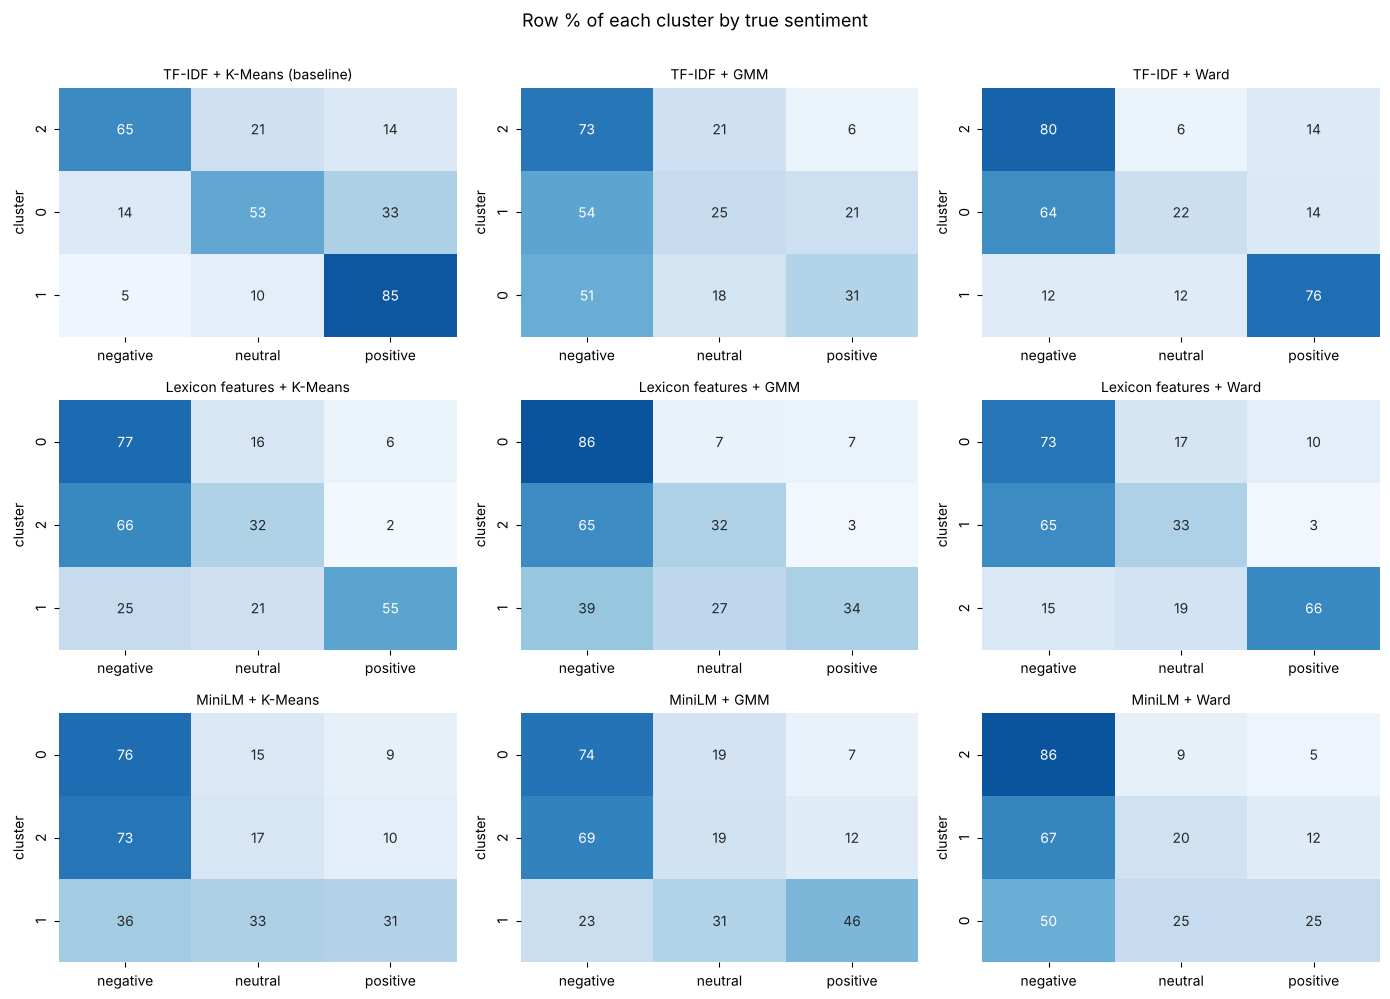

In [33]:
fig, axes = plt.subplots(len(REPS), 3, figsize=(14, 3.3 * len(REPS)))
for i, rep in enumerate(REPS):
    for j, algo in enumerate(ALGOS):
        lab = labels[(rep, algo)]
        ct = (pd.crosstab(lab, y, normalize='index') * 100).reindex(columns=CLASSES, fill_value=0).loc[order_clusters(lab)]
        sns.heatmap(ct, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, cbar=False, ax=axes[i, j])
        axes[i, j].set_title(f'{mname(rep, algo)}', fontsize=10); axes[i, j].set_xlabel(''); axes[i, j].set_ylabel('cluster')
plt.suptitle('Row % of each cluster by true sentiment', y=1.005, fontsize=13)
plt.tight_layout(); plt.show()

**t-SNE maps.** t-SNE places tweets that are close in the representation close on the page. It keeps *local* neighbourhoods but distorts global distances and cluster sizes, so read it for "are the sentiments mixed or separated?", not for exact geometry. We embed the same random 3,000 tweets for every representation (from the 50-d LSA/PCA versions for the text vectors, and from `X_scaled` for the lexicon features).

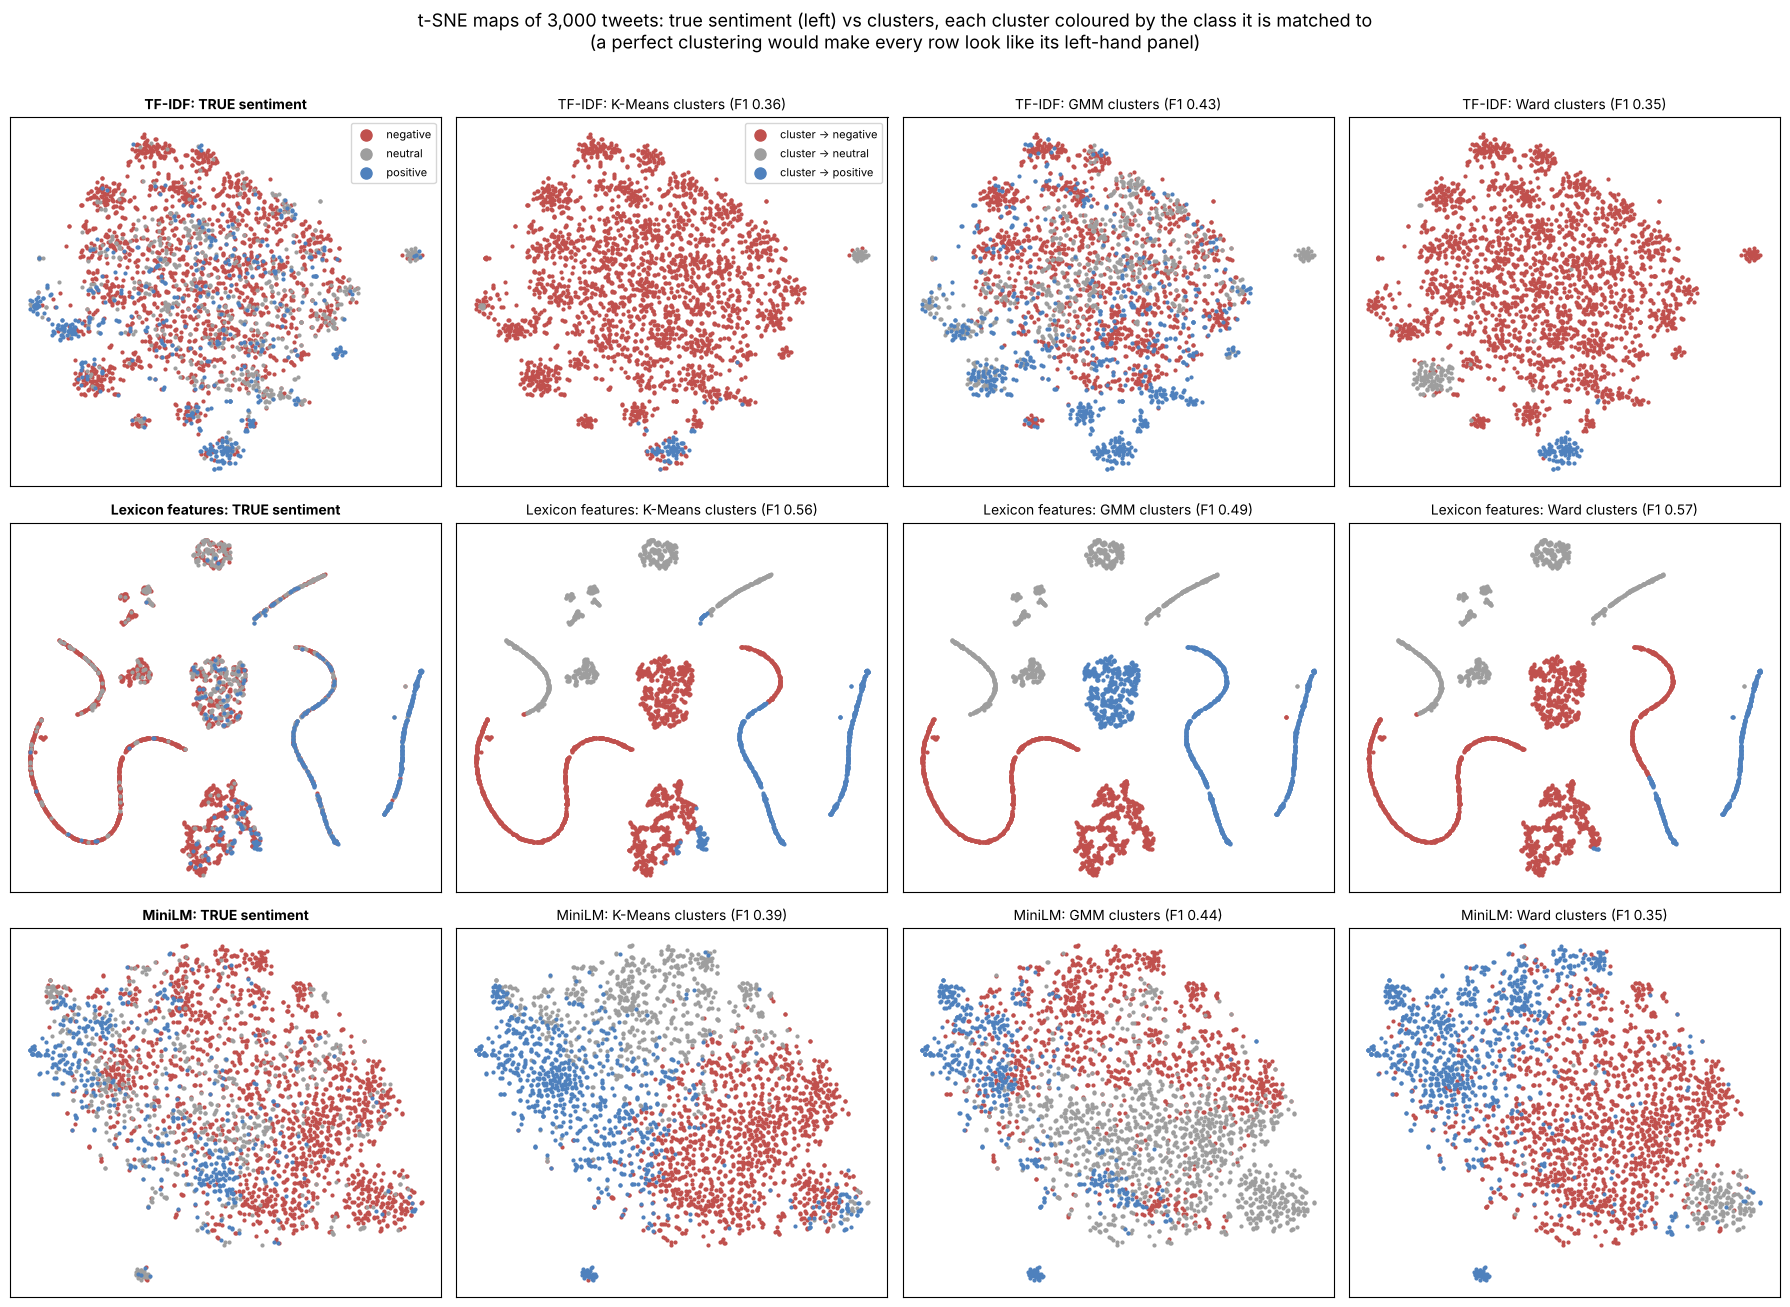

In [34]:
rng = np.random.default_rng(0)
s3 = rng.choice(len(df), 3000, replace=False)
TSNE_IN = {'TF-IDF': X_tfidf_lsa, 'Lexicon features': X_scaled, 'MiniLM': X_minilm50}
tsne_xy = {}
for rep in REPS:
    Xs = TSNE_IN[rep][s3]
    Xs = Xs + np.random.default_rng(1).normal(0, 1e-3, Xs.shape)    # tiny jitter: many lexicon rows are identical
    tsne_xy[rep] = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED).fit_transform(Xs)

clust_cols = ['#1b9e77', '#d95f02', '#7570b3']
fig, axes = plt.subplots(len(REPS), 4, figsize=(18, 4.3 * len(REPS)))
for i, rep in enumerate(REPS):
    P = tsne_xy[rep]
    for s in CLASSES:
        m = y[s3] == s; axes[i, 0].scatter(P[m, 0], P[m, 1], s=4, c=SENT_COLORS[s], label=s)
    axes[i, 0].set_title(f'{rep}: TRUE sentiment', fontsize=10, fontweight='bold')
    for j, algo in enumerate(ALGOS, start=1):
        matched = map_clusters(labels[(rep, algo)], y)[s3]      # colour each cluster by the class it is matched to
        for s in CLASSES:
            m = matched == s; axes[i, j].scatter(P[m, 0], P[m, 1], s=4, c=SENT_COLORS[s], label=f'cluster -> {s}')
        axes[i, j].set_title(f'{rep}: {algo} clusters (F1 {grid.loc[(rep, algo)].macro_F1:.2f})', fontsize=10)
    for a in axes[i]: a.set_xticks([]); a.set_yticks([])
axes[0, 0].legend(markerscale=4, loc='best', fontsize=8); axes[0, 1].legend(markerscale=4, loc='best', fontsize=8)
plt.suptitle('t-SNE maps of 3,000 tweets: true sentiment (left) vs clusters, each cluster coloured by the class it is matched to\n'
             '(a perfect clustering would make every row look like its left-hand panel)', y=1.01, fontsize=13)
plt.tight_layout(); plt.show()

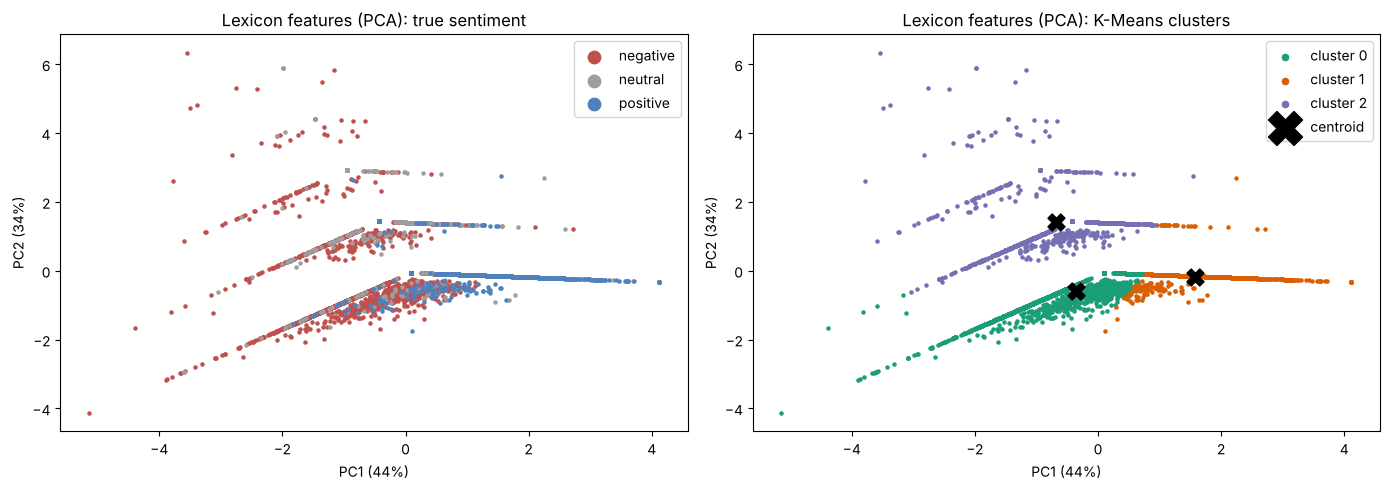

PC loadings:
     vader_neg  vader_pos  question_marks
PC1      -0.62       0.72           -0.31
PC2      -0.49      -0.05            0.87


In [35]:
# PCA view of the lexicon features: the axes are interpretable, unlike t-SNE
pca2 = PCA(n_components=2, random_state=SEED).fit(X_scaled); P2 = pca2.transform(X_scaled)
s4 = np.random.default_rng(0).choice(len(P2), 4000, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for s in CLASSES:
    m = y[s4] == s; ax[0].scatter(P2[s4][m, 0], P2[s4][m, 1], s=5, c=SENT_COLORS[s], label=s)
ax[0].legend(markerscale=4); ax[0].set_title('Lexicon features (PCA): true sentiment')
lab = labels[('Lexicon features', 'K-Means')]
for c in range(3):
    m = lab[s4] == c; ax[1].scatter(P2[s4][m, 0], P2[s4][m, 1], s=5, c=clust_cols[c], label=f'cluster {c}')
cent2 = pca2.transform(models[('Lexicon features', 'K-Means')].cluster_centers_)
ax[1].scatter(cent2[:, 0], cent2[:, 1], c='black', marker='X', s=150, label='centroid'); ax[1].legend(markerscale=2)
ax[1].set_title('Lexicon features (PCA): K-Means clusters')
for a in ax: a.set_xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]:.0%})'); a.set_ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]:.0%})')
plt.tight_layout(); plt.show()
print('PC loadings:'); print(pd.DataFrame(pca2.components_, index=['PC1', 'PC2'], columns=FEATURES).round(2))

**Reading the pictures (our run):**
- **TF-IDF (including the baseline):**
  - K-Means and Ward put 93–96% of tweets in one giant cluster. They split off two small "topic" groups: a thank-you group (85% positive with K-Means) and a "fleek/fleet" retweet campaign.
  - The GMM on LSA-50 gives three similar-sized clusters, but each is a mix of all three sentiments.
  - On the t-SNE map, the true sentiments are scattered among topic islands.
- **Lexicon features:** three readable clusters, found by all three algorithms.

  | Cluster (K-Means) | Size | Negative / Neutral / Positive | What it contains |
  |---|---|---|---|
  | Statements, no question | 7,762 | 77% / 16% / 6% | negative wording, no "?" |
  | Questions | 3,576 | 66% / 32% / 2% | every tweet has a "?" (1.22 on average) |
  | Praise | 3,301 | 25% / 21% / 55% | positive wording |

  - The t-SNE map breaks into separate islands (tweets with identical feature values), and each algorithm colours whole islands. Most islands are cleanly negative or positive. The question islands mix negative and neutral tweets, which is where the errors are.
  - The question cluster collects 37% of all neutral tweets, but two-thirds of it are negative questions ("why is my flight late?").
- **MiniLM:**
  - The true-sentiment map has a positive-leaning region (left) and a negative region (right), but neutral tweets are spread throughout.
  - The clusters cut the map into chunks that follow topic (customer-service calls, cancelled flights, thanks) more than sentiment.
  - Only the GMM finds a cluster where positive tweets are the largest group (46%).
- **PCA of the lexicon features:** the two axes are readable.
  - PC1 runs from negative wording (`vader_neg` −0.62) to positive wording (`vader_pos` +0.72), so it is a sentiment axis.
  - PC2 is the question axis (`question_marks` +0.87).
  - The K-Means centroids sit at the three corners: negative, positive and questioning.

## 11. Interpreting the clusters
The lexicon features are readable, so we use them as a **lens** for every model: whatever representation built a cluster, we can ask how negative, positive or questioning its tweets are (with the number of "!" and the tweet length added as descriptive statistics only). We also read each cluster's top words and example tweets.


> **Definitions used here** (see *List of definitions_v16.csv*): **B5** Standardisation · **B8** TF-IDF · **C12** Model-to-model agreement

In [36]:
# 11.1 Lexicon K-Means centroids in ORIGINAL units
km_lex = models[('Lexicon features', 'K-Means')]
cent = pd.DataFrame(scaler.inverse_transform(km_lex.cluster_centers_), columns=FEATURES)
lab = labels[('Lexicon features', 'K-Means')]
cent['size'] = np.bincount(lab)
cent = cent.join((pd.crosstab(lab, y, normalize='index') * 100).round(0).add_suffix(' %'))
cent.round(2)

,vader_neg,vader_pos,question_marks,size,negative %,neutral %,positive %
0,0.13,0.05,0.00,7762,77.0,16.0,6.0
1,0.01,0.39,0.03,3301,25.0,21.0,55.0
2,0.08,0.07,1.22,3576,66.0,32.0,2.0


In [37]:
# 11.2 Profile of the clusters of EVERY model: the 3 features plus two descriptive text statistics
#      ("!" count and length are NOT model inputs; they only help describe the clusters)
lens = feat.assign(exclaim=df['text_light'].str.count('!'), n_words=df['text_light'].str.split().str.len())
LENS = ['vader_neg', 'vader_pos', 'question_marks', 'exclaim', 'n_words']
prof = []
for rep in REPS:
    for algo in ALGOS:
        lab = labels[(rep, algo)]
        comp = pd.crosstab(lab, y, normalize='index').reindex(columns=CLASSES, fill_value=0)
        for rank, c in enumerate(order_clusters(lab)):
            prof.append({'model': f'{mname(rep, algo)}', 'cluster': f'C{c}', 'size': int((lab == c).sum()),
                         **lens.loc[lab == c, LENS].mean().round(2).to_dict(),
                         'neg %': round(100 * comp.loc[c, 'negative']), 'neu %': round(100 * comp.loc[c, 'neutral']),
                         'pos %': round(100 * comp.loc[c, 'positive'])})
profile = pd.DataFrame(prof).set_index(['model', 'cluster'])
profile

size  vader_neg  vader_pos  question_marks  exclaim  n_words  neg %  neu %  pos %
model                       cluster                                                                                    
TF-IDF + K-Means (baseline) C2       14069       0.09       0.12            0.32     0.31    16.87     65     21     14
                            C0         208       0.05       0.34            0.10     0.29     6.60     14     53     33
                            C1         362       0.01       0.48            0.02     0.85     8.11      5     10     85
TF-IDF + GMM                C2        7396       0.09       0.09            0.39     0.26    18.27     73     21      6
                            C1        3529       0.10       0.15            0.20     0.31    13.60     54     25     21
                            C0        3714       0.08       0.20            0.23     0.46    15.76     51     18     31
TF-IDF + Ward               C2         542       0.15       0.11            0.23     0.33    16.89     80      6     14
                            C0       13607       0.09       0.12            0.32     0.31    16.66     64     22     14
                            C1         490       0.02       0.42            0.08     0.80    11.77     12     12     76
Lexicon features + K-Means  C0        7762       0.13       0.05            0.00     0.25    17.34     77     16      6
                            C2        3576       0.08       0.07            1.22     0.22    18.10     66     32      2
                            C1        3301       0.01       0.39            0.03     0.62    12.82     25     21     55
Lexicon features + GMM      C0        5318       0.19       0.08            0.00     0.29    18.73     86      7      7
                            C2        3674       0.08       0.08            1.22     0.23    17.91     65     32      3
                            C1        5647       0.00       0.22            0.00     0.42    13.50     39     27     34
Lexicon features + Ward     C0        8867       0.11       0.08            0.00     0.27    17.32     73     17     10
                            C1        3668       0.08       0.08            1.22     0.23    17.93     65     33      3
                            C2        2104       0.00       0.47            0.00     0.70    10.59     15     19     66
MiniLM + K-Means            C0        3547       0.09       0.12            0.33     0.22    17.17     76     15      9
                            C2        6655       0.10       0.09            0.35     0.30    18.97     73     17     10
                            C1        4437       0.06       0.21            0.22     0.44    12.29     36     33     31
MiniLM + GMM                C0        5770       0.09       0.10            0.35     0.24    17.84     74     19      7
                            C2        6274       0.10       0.10            0.33     0.31    17.97     69     19     12
                            C1        2595       0.06       0.29            0.13     0.54    10.00     23     31     46
MiniLM + Ward               C2         918       0.11       0.08            0.38     0.27    19.26     86      9      5
                            C1        8734       0.10       0.10            0.34     0.31    18.09     67     20     12
                            C0        4987       0.08       0.19            0.23     0.36    13.23     50     25     25

In [38]:
# 11.3 Top words of each cluster (mean TF-IDF weight within the cluster), for the K-Means model of each representation
for rep in REPS:
    lab = labels[(rep, 'K-Means')]
    print(f'--- {rep} + K-Means ---')
    for c in order_clusters(lab):
        mean_w = np.asarray(X_tfidf[lab == c].mean(axis=0)).ravel()
        share = pd.Series(y[lab == c]).value_counts(normalize=True).reindex(CLASSES, fill_value=0)
        print(f'C{c} ({(lab == c).sum():,}; neg/neu/pos = {share.values.round(2)}):', ', '.join(vocab[mean_w.argsort()[::-1][:12]]))

--- TF-IDF + K-Means ---
C2 (14,069; neg/neu/pos = [0.65 0.21 0.14]): to, the, flight, you, for, on, and, my, is, in, it, of
C0 (208; neg/neu/pos = [0.14 0.53 0.33]): thanks, fleek, on fleek, fleet on, our fleet, fleet, our, on, rt our, rt, stop, this
C1 (362; neg/neu/pos = [0.05 0.1  0.85]): thank you, thank, you, you for, for, for the, the, much, great, will, great thank, you so
--- Lexicon features + K-Means ---
C0 (7,762; neg/neu/pos = [0.77 0.16 0.06]): to, the, and, flight, on, for, my, you, in, is, it, of
C2 (3,576; neg/neu/pos = [0.66 0.32 0.02]): to, you, the, flight, is, can, on, for, my, what, do, it
C1 (3,301; neg/neu/pos = [0.25 0.21 0.55]): thanks, you, thank, thank you, the, to, for, great, and, it, please, thanks for
--- MiniLM + K-Means ---
C0 (3,547; neg/neu/pos = [0.76 0.15 0.09]): to, the, for, you, and, on, is, it, customer, service, your, me
C2 (6,655; neg/neu/pos = [0.73 0.17 0.1 ]): flight, to, the, on, for, my, and, you, is, cancelled, in, of
C1 (4,437; neg/neu

In [39]:
# 11.4 Example tweets: the 3 tweets closest to each centroid of the embedding K-Means model
emb_rep = 'MiniLM'
km_q = models[(emb_rep, 'K-Means')]; lab = labels[(emb_rep, 'K-Means')]
dist_c = km_q.transform(INPUTS[emb_rep]['K-Means'])
for c in order_clusters(lab):
    print(f'\n{emb_rep} K-Means cluster C{c} ({(lab == c).sum():,} tweets):')
    members = np.where(lab == c)[0]
    for i in members[np.argsort(dist_c[members, c])[:3]]:
        print(f'   [{y[i]:8s}] {df.text_light[i][:140]}')


MiniLM K-Means cluster C0 (3,547 tweets):
   [negative] I tried to call your customer service line only to be kept in a que for over 45 mins.. please hold =we don't care
   [negative] Collectively since Friday I've been on hold with customer service for over 3 hrs. My issue is not resolved.. so frustrated!
   [negative] Is your reservation phone number working? Called 10x in the last 3 days, and haven’t gotten through.

MiniLM K-Means cluster C2 (6,655 tweets):
   [negative] . Worst flying experiences ever the past three days. Your airline needs to get it together. Lost a customer with me
   [negative] can a real person help me here? This customer service is poor. I'm at the mercy of someone since the flights are disappearing.
   [negative] you guys SUCK! Another Cancelled Flighted flight! Every flight with you has an issue!

MiniLM K-Means cluster C1 (4,437 tweets):
   [positive] Thanks for the timely service & great staff getting my wife and me to and from Cancun this past week for 

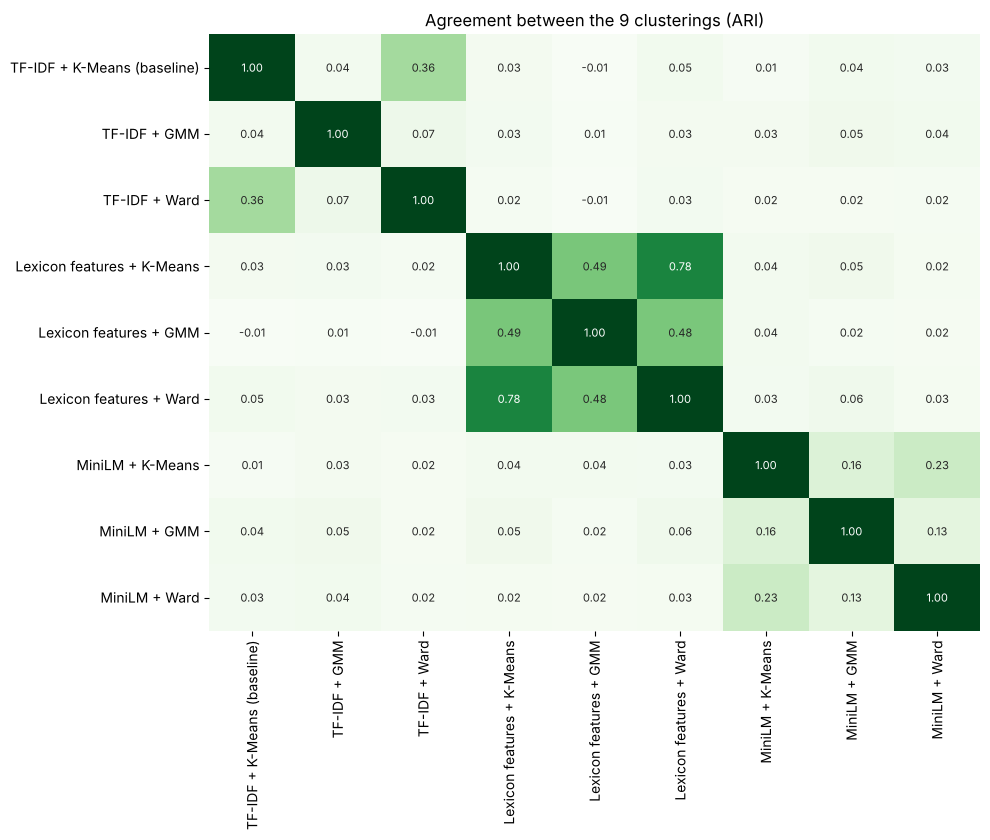

In [40]:
# 11.5 How similar are the 9 clusterings to each other? (ARI between models; no labels needed)
names = [f'{mname(r, a)}' for r in REPS for a in ALGOS]
L = [labels[(r, a)] for r in REPS for a in ALGOS]
agree = pd.DataFrame([[adjusted_rand_score(a, b) for b in L] for a in L], names, names)
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(agree, annot=True, fmt='.2f', cmap='Greens', vmin=0, vmax=1, cbar=False, ax=ax, annot_kws={'size': 8})
ax.set_title(f'Agreement between the {len(names)} clusterings (ARI)'); plt.tight_layout(); plt.show()

**Reading the interpretation (our run):**
- **Lexicon K-Means centroids (original units):**
  - **Statements, no question** (7,762 tweets): `vader_neg` 0.13, `vader_pos` 0.05, no "?".
  - **Questions** (3,576): 1.22 "?" per tweet, little sentiment wording.
  - **Praise** (3,301): `vader_pos` 0.39, almost no negative wording.

  Each cluster matches one of the README's tweet types: complaints, requests for information, praise.
- **Descriptive statistics** (not model inputs) support this. The praise cluster has the most "!" (0.62 per tweet) and the shortest tweets (12.8 words).
- **Through the lexicon lens, the other representations' clusters barely differ in sentiment.** For example, MiniLM K-Means clusters C0 and C2 have almost the same `vader_neg` (0.09 vs 0.10) and `vader_pos` (0.12 vs 0.09). They differ in *topic*, as the top words show: C0 is about "customer service" (being on hold, calling) and C2 about "flight … cancelled". TF-IDF K-Means is one giant cluster of function words plus two tiny topic groups.
- **On the lexicon features, the three algorithms largely agree** (model-to-model ARI 0.48–0.78; K-Means vs Ward 0.78). Across representations the agreement is only −0.01 to 0.06. So **the representation, much more than the algorithm, decides what structure is found.**

## 12. How the choices affect the results
Each experiment below changes **one** choice and keeps everything else fixed. The labels are used only to *score* the variants, after clustering; none of these results was used to choose k, the GMM covariance or the linkage (those choices were made label-free in Section 7).


> **Definitions used here** (see *List of definitions_v16.csv*): **D4** Ablation study · **C2** BIC · **D7** Dequantisation (jitter) · **D8** Curse of dimensionality

### 12.1 Representation (same algorithm) and 12.2 algorithm (same representation)

In [41]:
f1_grid = grid['macro_F1'].unstack()[ALGOS].loc[REPS]
ari_grid = grid['ARI'].unstack()[ALGOS].loc[REPS]
eff = pd.DataFrame({
    'mean F1 over algorithms':      f1_grid.mean(axis=1),
    'range of F1 over algorithms':  f1_grid.max(axis=1) - f1_grid.min(axis=1),
    'mean ARI over algorithms':     ari_grid.mean(axis=1)})
print('Effect of the REPRESENTATION (rows) and spread caused by the algorithm:'); print(eff.round(3), '\n')
eff_a = pd.DataFrame({'mean F1 over representations': f1_grid.mean(axis=0),
                      'range of F1 over representations': f1_grid.max(axis=0) - f1_grid.min(axis=0),
                      'mean ARI over representations': ari_grid.mean(axis=0)})
print('Effect of the ALGORITHM (rows) and spread caused by the representation:'); print(eff_a.round(3))

Effect of the REPRESENTATION (rows) and spread caused by the algorithm:
                  mean F1 over algorithms  range of F1 over algorithms  mean ARI over algorithms
representation                                                                                  
TF-IDF                              0.379                        0.084                     0.066
Lexicon features                    0.538                        0.080                     0.157
MiniLM                              0.391                        0.092                     0.073 

Effect of the ALGORITHM (rows) and spread caused by the representation:
           mean F1 over representations  range of F1 over representations  mean ARI over representations
algorithm                                                                                               
K-Means                           0.438                             0.204                          0.116
GMM                               0.451               

### 12.3 Scaling the lexicon features

In [42]:
sc_rows = {}
for algo, fit in [('K-Means', lambda X: KMeans(3, n_init=20, random_state=SEED).fit_predict(X)),
                  ('Ward',    lambda X: AgglomerativeClustering(3, linkage='ward').fit_predict(X))]:
    for name, X in [('unscaled', feat.values), ('scaled', X_scaled)]:
        e = evaluate(fit(X)); sc_rows[(algo, name)] = {k: e[k] for k in ['macro_F1', 'ARI', 'NMI', 'sizes']}
pd.DataFrame(sc_rows).T

macro_F1       ARI       NMI               sizes
K-Means unscaled  0.341448 -0.005662  0.045133  10965 / 3010 / 664
        scaled    0.563055  0.194898  0.164694  7762 / 3301 / 3576
Ward    unscaled  0.341448 -0.005662  0.045133  10965 / 664 / 3010
        scaled    0.565279  0.182042  0.157142  8867 / 3668 / 2104

### 12.4 GMM choices: covariance type, number of dimensions, and discrete features

In [43]:
# (a) Covariance type: BIC (used to choose) next to the ARI / macro-F1 it leads to (for the write-up only)
cov_rows = []
for rep in REPS:
    X = INPUTS[rep]['GMM']
    for cov in COV_TYPES:
        e = evaluate(gmm_fits[(rep, cov)].predict(X))
        cov_rows.append({'representation': rep, 'covariance': cov, 'BIC': round(bic_tab[(rep, cov)]),
                         'chosen by BIC': '✓' if best_cov[rep] == cov else '', 'macro_F1': e['macro_F1'], 'ARI': e['ARI']})
pd.DataFrame(cov_rows).set_index(['representation', 'covariance']).round(3)

BIC chosen by BIC  macro_F1    ARI
representation   covariance                                        
TF-IDF           spherical   -923001                   0.360  0.009
                 diag       -1012056                   0.462  0.147
                 tied        -943149                   0.353  0.005
                 full       -1192968             ✓     0.431  0.083
Lexicon features spherical     47471                   0.555  0.220
                 diag         -98409                   0.486  0.095
                 tied         110464                   0.532  0.130
                 full         -98878             ✓     0.486  0.095
MiniLM           spherical  -1420619                   0.357 -0.003
                 diag       -1533992                   0.368  0.053
                 tied       -1516851                   0.371  0.013
                 full       -1585223             ✓     0.387  0.038

In [44]:
# (b) Number of PCA dimensions given to the GMM (MiniLM embeddings, covariance chosen in Section 7.2)
dim_rows = {}
pca_q_big = PCA(n_components=100, random_state=SEED).fit(X_minilm)
Xq100 = pca_q_big.transform(X_minilm)
for d in [5, 10, 25, 50, 100]:
    Xd = Xq100[:, :d]
    g = GaussianMixture(3, covariance_type=best_cov['MiniLM'], n_init=3, random_state=SEED).fit(Xd)
    e = evaluate(g.predict(Xd))
    dim_rows[d] = {'variance kept': pca_q_big.explained_variance_ratio_[:d].sum(), 'macro_F1': e['macro_F1'], 'ARI': e['ARI'], 'sizes': e['sizes']}
pd.DataFrame(dim_rows).T.rename_axis('PCA dims')

,variance kept,macro_F1,ARI,sizes
PCA dims,,,,
5,0.172939,0.379994,0.011639,3983 / 5277 / 5379
10,0.258214,0.385015,0.039714,4126 / 5148 / 5365
25,0.41079,0.396996,0.064116,6286 / 3793 / 4560
50,0.555747,0.386576,0.037932,5472 / 3074 / 6093
100,0.725252,0.390362,0.075817,7496 / 2453 / 4690


In [45]:
# (c) Discrete count features: why does the lexicon GMM split on exact zeros, and does a tiny jitter fix it?
g_lex = models[('Lexicon features', 'GMM')]; lab_g = labels[('Lexicon features', 'GMM')]
count_feats = ['question_marks']
print('Share of tweets with value 0, per GMM cluster (lexicon features):')
print(pd.DataFrame({f: (feat[f] == 0).groupby(lab_g).mean() for f in count_feats}).round(2))
print('Share of tweets with vader_neg = 0 / vader_pos = 0, per GMM cluster:')
print(pd.DataFrame({f: (feat[f] == 0).groupby(lab_g).mean() for f in ['vader_neg', 'vader_pos']}).round(2), '\n')

# Dequantisation: add uniform noise in [0, 1) to the integer counts so no feature is constant inside a cluster (label-free)
feat_j = feat.copy().astype(float)
rng = np.random.default_rng(SEED)
for f in count_feats:
    feat_j[f] = feat_j[f] + rng.uniform(0, 1, len(feat_j))
X_j = StandardScaler().fit_transform(feat_j)
bic_j = {cov: GaussianMixture(3, covariance_type=cov, n_init=3, random_state=SEED).fit(X_j).bic(X_j) for cov in COV_TYPES}
cov_j = min(bic_j, key=bic_j.get)
lab_j = GaussianMixture(3, covariance_type=cov_j, n_init=5, random_state=SEED).fit(X_j).predict(X_j)
jit = pd.DataFrame({'GMM on lexicon features (main)': evaluate(lab_g),
                    f'GMM on jittered lexicon features ({cov_j})': evaluate(lab_j),
                    'K-Means on lexicon features (main)': evaluate(labels[('Lexicon features', 'K-Means')])}).T
jit[['macro_F1', 'ARI', 'NMI', 'sizes']]

Share of tweets with value 0, per GMM cluster (lexicon features):
   question_marks
0             1.0
1             1.0
2             0.0
Share of tweets with vader_neg = 0 / vader_pos = 0, per GMM cluster:
   vader_neg  vader_pos
0       0.00       0.52
1       1.00       0.35
2       0.52       0.57 



,macro_F1,ARI,NMI,sizes
GMM on lexicon features (main),0.485751,0.095248,0.126948,5318 / 5647 / 3674
GMM on jittered lexicon features (full),0.367634,0.029947,0.116564,3275 / 6933 / 4431
K-Means on lexicon features (main),0.563055,0.194898,0.164694,7762 / 3301 / 3576


### 12.5 Linkage for agglomerative clustering (lexicon features)

In [46]:
link_rows = {}
for link in ['ward', 'complete', 'average', 'single']:
    lab = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X_scaled)
    e = evaluate(lab); link_rows[link] = {k: e[k] for k in ['sizes', 'macro_F1', 'ARI']}
pd.DataFrame(link_rows).T

,sizes,macro_F1,ARI
ward,8867 / 3668 / 2104,0.565279,0.182042
complete,659 / 13336 / 644,0.267333,-0.051648
average,14565 / 24 / 50,0.257149,-0.004179
single,14637 / 1 / 1,0.256869,-0.000166


### 12.6 Feature ablation (lexicon features, K-Means): does each feature earn its place?

In [47]:
def score_cols(cols):
    lab = KMeans(3, n_init=20, random_state=SEED).fit_predict(StandardScaler().fit_transform(feat[cols]))
    e = evaluate(lab); return {'ARI': e['ARI'], 'macro_F1': e['macro_F1'], 'sizes': e['sizes']}
abl = {'All 3 features': score_cols(FEATURES)}
for c in FEATURES:
    abl[f'Without {c}' + (' (= VADER only)' if c == 'question_marks' else '')] = score_cols([x for x in FEATURES if x != c])
abl = pd.DataFrame(abl).T
abl['ARI_change'] = abl['ARI'] - abl.loc['All 3 features', 'ARI']
abl['F1_change'] = abl['macro_F1'] - abl.loc['All 3 features', 'macro_F1']
abl.round(3)

,ARI,macro_F1,sizes,ARI_change,F1_change
All 3 features,0.194898,0.563055,7762 / 3301 / 3576,0.0,0.0
Without vader_neg,0.180869,0.561829,3604 / 8483 / 2552,-0.014029,-0.001226
Without vader_pos,-0.016084,0.411083,7936 / 3224 / 3479,-0.210982,-0.151972
Without question_marks (= VADER only),0.124034,0.514601,8099 / 2683 / 3857,-0.070864,-0.048454


**How the choices affect the results (our run):**
1. **Representation matters most.**
   - Mean macro-F1 over the three algorithms: lexicon features 0.538, MiniLM 0.391, TF-IDF 0.379.
   - With a fixed algorithm, the representation changes F1 by 0.20 (K-Means) and 0.22 (Ward).
2. **The algorithm matters less.**
   - Within one representation, the algorithm changes F1 by only 0.08–0.09.
   - The GMM helps the weak representations (TF-IDF 0.359 → 0.431, MiniLM 0.391 → 0.437), because it can form unequal, elongated clusters. On the lexicon features it learns a shortcut instead (point 4).
   - K-Means and Ward are level on the lexicon features.
3. **Scaling is essential.**
   - Unscaled, the "?" count (standard deviation 0.59) outweighs the VADER scores (0.12, 0.18). K-Means and Ward then simply split the tweets into 0, 1 and 2+ question marks (10,965 / 3,010 / 664), with F1 0.341 and ARI −0.006.
   - Standardising raises K-Means to 0.563 / 0.195.
4. **GMM choices:**
   - **Covariance:** BIC picks the best *density* model, not the best *sentiment* model. For the lexicon features, a spherical covariance would have given F1 0.555 / ARI 0.220, against 0.486 / 0.095 for the BIC choice (full). We keep the label-free BIC choice and report the gap.
   - **Dimensions:** giving the MiniLM GMM 5 to 100 PCA components changes F1 only between 0.380 and 0.397. (At 50 dimensions with `n_init=3` it scores 0.387, not the 0.437 of the main model with `n_init=5`, so the GMM is also sensitive to its starting points.)
   - **Discrete values:** the lexicon GMM's clusters sit on exact values. Two clusters contain no "?" at all and the third only tweets with a "?". One cluster has `vader_neg` = 0 for every tweet.
   - **Jitter:** removing that shortcut with label-free jitter does **not** help (F1 0.368, ARI 0.030).
5. **Linkage:** only Ward works. Complete, average and single linkage leave one cluster with 13,336, 14,565 and 14,637 of the 14,639 tweets (F1 0.26–0.27).
6. **Feature ablation** (lexicon K-Means): every feature lowers ARI when it is removed.

   | Features | ARI | Macro-F1 |
   |---|---|---|
   | All 3 | 0.195 | 0.563 |
   | Without `vader_neg` | 0.181 | 0.562 |
   | Without `question_marks` (= VADER only) | 0.124 | 0.515 |
   | Without `vader_pos` | −0.016 | 0.411 |

   - `vader_pos` is essential: without it there is no praise cluster.
   - `question_marks` adds the question cluster (+0.071 ARI).
   - `vader_neg` adds the least (+0.014 ARI), because tweets with neither praise nor a question are mostly complaints anyway.

## 13. Uncertainty and robustness
### 13.1 Are clearly expressed tweets clustered better? (all 9 models)
For each model we compute ARI and the agreement rate (tweet's label = its cluster's majority label) within bins of `sentiment_confidence`.


> **Definitions used here** (see *List of definitions_v16.csv*): **C1** ARI · **C11** Spearman ρ · **A3** GMM

Tweets per confidence bin: {'<0.6': 238, '0.6-0.8': 3943, '0.8-<1': 14, '=1': 10444}


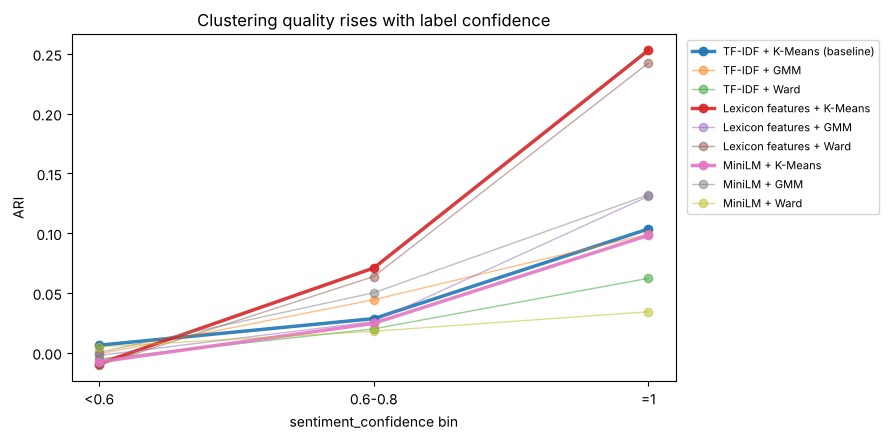

,ARI <0.6,ARI 0.6-0.8,ARI =1,agree (conf=1),agree (conf<0.8),mean conf | agrees,mean conf | disagrees
TF-IDF + K-Means (baseline),0.006,0.029,0.104,0.732,0.452,0.932,0.840
TF-IDF + GMM,-0.001,0.044,0.099,0.707,0.427,0.933,0.844
TF-IDF + Ward,-0.005,0.020,0.062,0.730,0.444,0.933,0.839
Lexicon features + K-Means,-0.009,0.071,0.253,0.778,0.484,0.932,0.828
Lexicon features + GMM,-0.002,0.026,0.131,0.707,0.427,0.933,0.844
Lexicon features + Ward,-0.010,0.064,0.242,0.787,0.486,0.932,0.825
MiniLM + K-Means,-0.008,0.025,0.098,0.707,0.427,0.933,0.844
MiniLM + GMM,0.000,0.050,0.132,0.747,0.469,0.932,0.837
MiniLM + Ward,0.005,0.018,0.034,0.707,0.427,0.933,0.844


In [48]:
conf = df['sentiment_confidence'].values
bins = pd.cut(conf, [0, 0.6, 0.8, 0.999, 1.0], labels=['<0.6', '0.6-0.8', '0.8-<1', '=1'])
print('Tweets per confidence bin:', pd.Series(bins).value_counts().reindex(['<0.6', '0.6-0.8', '0.8-<1', '=1']).to_dict())
unc_ari, unc_agree = {}, {}
for rep in REPS:
    for algo in ALGOS:
        lab = labels[(rep, algo)]
        dom = pd.crosstab(lab, y).idxmax(axis=1)
        agrees = pd.Series(lab).map(dom).values == y
        name = f'{mname(rep, algo)}'
        unc_ari[name]   = {b: adjusted_rand_score(y[bins == b], lab[bins == b]) for b in ['<0.6', '0.6-0.8', '=1']}
        unc_agree[name] = {'agree (conf=1)': agrees[bins == '=1'].mean(), 'agree (conf<0.8)': agrees[conf < 0.8].mean(),
                           'mean conf | agrees': conf[agrees].mean(), 'mean conf | disagrees': conf[~agrees].mean()}
unc = pd.DataFrame(unc_ari).T.add_prefix('ARI ').join(pd.DataFrame(unc_agree).T)
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, r in pd.DataFrame(unc_ari).T.iterrows():
    ax.plot(['<0.6', '0.6-0.8', '=1'], r.values, 'o-', lw=2.5 if 'K-Means' in name else 1, alpha=0.9 if 'K-Means' in name else 0.5, label=name)
ax.set_ylabel('ARI'); ax.set_xlabel('sentiment_confidence bin'); ax.set_title('Clustering quality rises with label confidence')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8); plt.tight_layout(); plt.show()
unc.round(3)

### 13.2 Do the GMM's probabilities reflect label ambiguity?

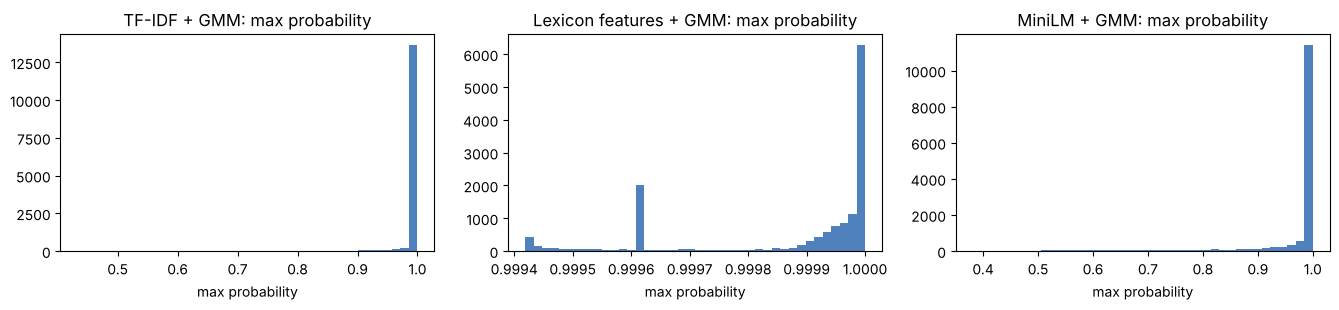

,covariance,share max prob > 0.95,"Spearman rho (max prob, confidence)",agree rate | max prob < 0.9,agree rate | max prob >= 0.9
TF-IDF,full,0.957238,0.0176,0.610984,0.627447
Lexicon features,full,1.0,0.059569,NaN,0.626955
MiniLM,full,0.848282,0.020623,0.608561,0.674906


In [49]:
soft_rows = {}
for rep in REPS:
    p = probas[rep]; lab = labels[(rep, 'GMM')]
    maxp = p.max(axis=1)
    dom = pd.crosstab(lab, y).idxmax(axis=1); agrees = pd.Series(lab).map(dom).values == y
    rho, pval = spearmanr(maxp, conf)
    unsure = maxp < 0.9
    soft_rows[rep] = {'covariance': best_cov[rep], 'share max prob > 0.95': (maxp > 0.95).mean(),
                      'Spearman rho (max prob, confidence)': rho,
                      'agree rate | max prob < 0.9': agrees[unsure].mean() if unsure.any() else np.nan,
                      'agree rate | max prob >= 0.9': agrees[~unsure].mean()}
fig, axes = plt.subplots(1, len(REPS), figsize=(4.5 * len(REPS), 3.2))
for ax, rep in zip(axes, REPS):
    ax.hist(probas[rep].max(axis=1), bins=40, color='#4f81bd'); ax.set_title(f'{rep} + GMM: max probability'); ax.set_xlabel('max probability')
plt.tight_layout(); plt.show()
pd.DataFrame(soft_rows).T

### 13.3 Error analysis: confident labels in the 'wrong' cluster

In [50]:
best_name = ('Lexicon features', 'K-Means')              # the recommended model (Section 9.3)
lab = labels[best_name]
dom = pd.crosstab(lab, y).idxmax(axis=1); pred = map_clusters(lab, y)
err = df.assign(cluster=lab, matched_class=pred)[(pred != y) & (conf == 1)]
print(f'Recommended model: {best_name[0]} + {best_name[1]}')
print('High-confidence mismatches by (true -> matched cluster class):')
print(pd.crosstab(err['airline_sentiment'], err['matched_class']))
err[['text_light', 'airline_sentiment', 'matched_class']].sample(12, random_state=3)

Recommended model: Lexicon features + K-Means
High-confidence mismatches by (true -> matched cluster class):
matched_class      negative  neutral  positive
airline_sentiment                             
negative                  0     1842       524
neutral                 627        0       277
positive                213       29         0


,text_light,airline_sentiment,matched_class
3946,", wtf is your username and/or email addr signin STILL unavailable? Been trying to login since Sunday",negative,neutral
5487,take me here,neutral,negative
10187,Our flight was Cancelled Flightled & chaos abounds. I am in good humour. Please give me free everything to appease me.,negative,positive
2016,flighted delayed for hours. 10pm arrival to Vegas is now 4am. Did you seriously lose my luggage??,negative,neutral
11923,got back eventually! Was a rollercoaster. Once I got to the airport & got to speak to someone things got fixed very ...,positive,negative
4123,"so I wasted 40mins filling in 2 online forms you are telling me you didn't receive, how do I know this won't happen ...",negative,neutral
12129,we done it with 1 truck.. No biggie 😄,positive,negative
13828,"I paid extra $ for my seat & the monitor didn't work from on AA11. How about a refund on the seat? Conf #: MDBEEI, M...",negative,neutral
2358,"ok so what is being done about my experience? My family had a terrible experience for $1,200. It's kind of like bein...",negative,neutral
937,"doesn't charge ticket change fees. Do they not incur the same mysterious ""costs"" that you incur, ?",negative,neutral


### 13.4 Stability: seeds, subsamples and held-out tweets

In [51]:
from sklearn.model_selection import train_test_split
stab = {}
for rep in REPS:
    Xk, Xg, Xw = INPUTS[rep]['K-Means'], INPUTS[rep]['GMM'], INPUTS[rep]['Ward']
    a_km = [adjusted_rand_score(y, KMeans(3, n_init=10, random_state=s).fit_predict(Xk)) for s in range(5)]
    a_gm = [adjusted_rand_score(y, GaussianMixture(3, covariance_type=best_cov[rep], n_init=2, random_state=s).fit(Xg).predict(Xg)) for s in range(5)]
    a_wd = []
    for s in range(3):                                          # Ward is deterministic -> refit on 80% subsamples
        ix = np.random.default_rng(s).choice(len(df), int(0.8 * len(df)), replace=False)
        a_wd.append(adjusted_rand_score(y[ix], AgglomerativeClustering(3, linkage='ward').fit_predict(Xw[ix])))
    tr, te = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED)
    km = KMeans(3, n_init=20, random_state=SEED).fit(Xk[tr])
    stab[rep] = {'K-Means ARI (5 seeds)': f'{np.mean(a_km):.3f} ± {np.std(a_km):.3f}',
                 'GMM ARI (5 seeds)':     f'{np.mean(a_gm):.3f} ± {np.std(a_gm):.3f}',
                 'Ward ARI (3 × 80% subsamples)': f'{np.mean(a_wd):.3f} ± {np.std(a_wd):.3f}',
                 'K-Means train / held-out ARI': f'{adjusted_rand_score(y[tr], km.labels_):.3f} / {adjusted_rand_score(y[te], km.predict(Xk[te])):.3f}'}
pd.DataFrame(stab).T

,K-Means ARI (5 seeds),GMM ARI (5 seeds),Ward ARI (3 × 80% subsamples),K-Means train / held-out ARI
TF-IDF,0.031 ± 0.047,0.074 ± 0.006,0.041 ± 0.002,0.059 / 0.051
Lexicon features,0.195 ± 0.000,0.095 ± 0.000,0.149 ± 0.053,0.197 / 0.187
MiniLM,0.079 ± 0.001,0.081 ± 0.035,-0.005 ± 0.020,0.079 / 0.077


**Uncertainty and robustness (our run):**
- **Clearly expressed tweets are clustered much better by every model.**
  - ARI is about 0 for tweets with confidence < 0.6, and highest at confidence = 1 (lexicon K-Means 0.253, lexicon Ward 0.242).
  - In every model, tweets that agree with their cluster's majority label have a higher mean confidence (≈ 0.93) than those that disagree (≈ 0.83–0.84).
  - This answers the README's spectrum question.
- **GMM probabilities do not track label ambiguity.**
  - The GMMs are over-confident: the maximum probability is above 0.95 for 96% (TF-IDF), 100% (lexicon) and 85% (MiniLM) of tweets.
  - The Spearman correlation with `sentiment_confidence` is about 0 (0.02 to 0.06).
- **Error analysis** (recommended model, lexicon K-Means, confidence = 1):
  - The largest group (1,842) is **negative tweets in the question cluster**: complaints phrased as questions ("Did you seriously lose my luggage??", "How can you not know where my bags are?").
  - Next come 627 neutral tweets in the no-question cluster: statements with some negative wording.
  - Then 524 negative tweets in the praise cluster: complaints that contain "please", "help" or "thanks", or sarcasm ("I am in good humour. Please give me free everything").
- **Stability:**
  - Lexicon K-Means and GMM are perfectly stable across seeds (ARI ± 0.000).
  - TF-IDF K-Means is not (0.031 ± 0.047 with `n_init=10`): which tiny topic group gets split off changes with the start.
  - Ward is deterministic, but on 80% subsamples it varies noticeably on the lexicon features (0.149 ± 0.053).
- **Held-out tweets:** fitting K-Means on 80% and assigning the other 20% gives almost the same ARI (lexicon 0.197 train vs 0.187 test). The clusters generalise.

## 14. Save the models

In [52]:
import joblib
joblib.dump({'scaler': scaler, 'kmeans': models[('Lexicon features', 'K-Means')], 'feature_names': FEATURES},
            'kmeans_sentiment_model.joblib')
joblib.dump({'tfidf': tfidf, 'svd50': svd50, 'scaler': scaler, 'feature_names': FEATURES,
             'pca_minilm': pca_minilm,
             'kmeans': {r: models[(r, 'K-Means')] for r in REPS},
             'gmm':    {r: models[(r, 'GMM')] for r in REPS},
             'ward_cluster_means': {r: np.vstack([np.asarray(INPUTS[r]['Ward'][labels[(r, 'Ward')] == c].mean(axis=0)).ravel()
                                                  for c in range(3)]) for r in REPS}},
            'all_models_v16.joblib')
results.round(4).to_csv('model_comparison_v16.csv', index=False)
print('Saved kmeans_sentiment_model.joblib, all_models_v16.joblib and model_comparison_v16.csv')

Saved kmeans_sentiment_model.joblib, all_models_v16.joblib and model_comparison_v16.csv


## 15. Summary and key takeaways
1. **The README rule and the README's own description shape the design.**
   - The labels are used only from Section 9 on, and every modelling choice (k, GMM covariance, linkage) is made without labels.
   - The lexicon features turn the README's three tweet types into one readable feature each: praise → `vader_pos`, complaints → `vader_neg`, requests for information → `question_marks`.
2. **Representation matters far more than algorithm.**
   - Mean macro-F1 is 0.538 for the lexicon features against 0.38–0.39 for TF-IDF and MiniLM.
   - The representation changes F1 by up to 0.22, the algorithm by only 0.08–0.09.
   - Different representations find almost unrelated groupings (ARI between them 0.06 or less).
3. **General-purpose representations group by topic, not sentiment.** TF-IDF (the baseline) produces one giant cluster plus small topic groups. MiniLM separates customer-service, cancellation and thank-you tweets. Neither isolates neutral tweets.
4. **Recommended model: the three scaled lexicon features with K-Means.**
   - Macro-F1 0.563, ARI 0.195, NMI 0.165: **+0.204 macro-F1 and +0.120 ARI over the TF-IDF + K-Means baseline**.
   - Perfectly stable across seeds, and it generalises to held-out tweets (ARI 0.197 → 0.187).
   - Three readable clusters: statements/complaints, questions, praise.
   - Ward is level on macro-F1 (0.565) but less stable and has no `predict()`.
5. **A few readable features can be enough.** Three features from one published lexicon plus a punctuation count beat word counts and a pre-trained transformer. The ablation shows `vader_pos` is essential and `question_marks` adds the question cluster.
6. **Each algorithm has a characteristic behaviour.**
   - K-Means is fast, stable and balanced on good features.
   - The GMM helps weak representations but latches onto exact values ("no '?'", "no negative wording"), and its probabilities are over-confident.
   - Ward agrees closely with K-Means on the lexicon features but varies on subsamples; only the Ward linkage works.
7. **Choices matter in predictable ways.**
   - Scaling adds about 0.22 macro-F1 for K-Means: without it, the clusters are just "0, 1, 2+ question marks".
   - BIC chooses the best density model, not the best sentiment model.
   - The number of PCA dimensions barely matters for the MiniLM GMM.
8. **Neutral is the hardest class.**
   - The question cluster is the closest thing to a neutral cluster, but two-thirds of it is negative questions. Neutral F1 is 0.34 for the recommended model.
   - Every model clusters high-confidence tweets far better than ambiguous ones.
9. **The data limit what any model can reach.** Neutral has no vocabulary of its own, airline is a confounder, and 25 duplicated texts carry conflicting labels.

**Limitations to state.**
- VADER is general-purpose: it scores the airline name *united* and requests such as *help* and *please* as positive.
- Sarcasm and complaints phrased as questions are misplaced.
- The compact three-feature set was adopted after comparing several feature subsets, so the final choice was also informed by evaluation results. The README-based rationale (Section 4.2) motivates it independently.